In [1]:
from modules.dataset.make_dataset import make_dataset, dataset_split_by_recording, stratified_recording_folds, NpzDataPipeline, AugmentedSubset, dataset_split
from modules.nn import CoralOrdinal, DefaultCNN, coral_pos_weights, coral_targets, ordinal_oof_metrics, ordinal_predict, BranchedCoughCNN
import polars as pl
import numpy as np
import torch
from torchinfo import summary
from torch.utils.data import Subset
import torch.nn as nn
import torch.optim as optim
from typing import Sequence
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

In [2]:
dataset: NpzDataPipeline = NpzDataPipeline("data\\final_processed_dataset.npz")
device: torch.types.Device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [3]:
import os

# ---- Crash-proof run state: per-epoch autosave + resume (train_ordinal) ----
RUN_STATE_DIR: str = "run_state_3class"
os.makedirs(RUN_STATE_DIR, exist_ok=True)

def _ckpt_path(name: str) -> str:
    return os.path.join(RUN_STATE_DIR, f"{name}_latest.pth.tar")

def _atomic_torch_save(obj: dict, path: str) -> None:
    tmp: str = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)  # crash mid-write never corrupts the good file


In [4]:
# ---- Experiment setup (shared) ----
from modules.dataset.make_dataset import AugmentedSubset, aug_probs_from_counts
from modules.preprocessing.audio_process import WaveformAugmentor, SpecAugmentations, MelSpectrogramPipeline, SpectMFCCPipeline, trim_tile, mixup_waveforms
from tqdm.auto import tqdm

num_epochs: int = 30  # epoch cap for ALL runs; early stop (15/3) lives in train_ordinal
N_FOLDS: int = 5
LOSS_TOP_N: int = 3  # lowest-val-loss checkpoints SAVED per fold; _vloss0 is the best
SEED: int = 42  # identical split across all experiments
BATCH_SIZE: int = 128

# n_mel=64 per Chang et al. (research_results.md fix #6): 64 mel bins @ 16 kHz
mel_train_plain: SpectMFCCPipeline = SpectMFCCPipeline(combind=True).to(device)  # no spec aug
mel_eval: SpectMFCCPipeline = SpectMFCCPipeline(combind=True).to(device)         # plain for validation

# speed: compile only the eval mel path; train paths stay eager (spec-aug masks/augmentor randomize per step)
mel_eval = torch.compile(mel_eval) if device.type == "cuda" else mel_eval  # CPU inductor needs MSVC cl.exe; skip
torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")


In [5]:
# ---- Recording-wise 5-fold CV setup (replaces the single 80/10/10 split) ----
# Recording-grouped, rank-stratified folds. The old test split survives only as
# the pool definition: train+val recordings form the CV pool, test stays held out.
# Every reported metric comes from pooled out-of-fold predictions, aggregated to
# the RECORDING level before anything is computed.

dataset.load_data()
dataset.load_paths()

train_subset, val_subset, test_subset = dataset_split_by_recording(dataset, dataset.paths, 0.8, 0.1, seed=SEED)

# rank mapping: healthy=low(0), symptomatic=med(1), COVID-19=high(2).
# npz encode order is 0=healthy, 1=COVID-19, 2=symptomatic -> explicit map, never assume.
RANK: dict[int, int] = {0: 0, 1: 2, 2: 1}
RANK_INV: dict[int, str] = {0: "low (healthy)", 1: "med (symptomatic)", 2: "high (COVID-19)"}
LABELS_INV = {0: "healthy", 1: "COVID-19", 2: "symptomatic"}
print("RANK map:", {LABELS_INV[k]: v for k, v in RANK.items()})

cv_pool: list[int] = [i for s in (train_subset, val_subset) for i in s.indices]

# recording index: path -> pool positions; recordings are single-label (npz blocks are per class)
rec_idx: dict[str, list[int]] = {}
for p in cv_pool:
    rec_idx.setdefault(dataset.paths[p], []).append(p)
rec_rank_of: dict[str, int] = {}
for path, idxs in rec_idx.items():
    labs = {int(dataset.labels[i]) for i in idxs}
    assert len(labs) == 1, f"recording {path} has mixed labels {labs} — grouping assumption broken"
    rec_rank_of[path] = RANK[next(iter(labs))]

cv_labels: list[int] = [rec_rank_of[dataset.paths[i]] for i in cv_pool]  # stratify on RANKS, not raw labels
FOLDS: list[tuple[list[int], list[int]]] = stratified_recording_folds(
    [dataset.paths[i] for i in cv_pool], cv_labels, n_splits=N_FOLDS, seed=SEED
)

# ---- Oversampling: repeat minority-class train indices until every class matches ----
# the largest class's count (full balance; ~15x COVID / ~3.7x symptomatic naturally).
# TRAIN-side only — val keeps the natural distribution (duplicates there would
# inflate metrics). Repetition (not loss weighting) composes with augmentation:
# every repeated draw gets a fresh random augment pass.
def oversample_balance(positions: Sequence[int]) -> list[int]:
    by_cls: dict[int, list[int]] = {0: [], 1: [], 2: []}
    for p in positions:
        by_cls[int(dataset.labels[p])].append(p)
    natural = {k: len(v) for k, v in by_cls.items()}
    target = max(natural.values())
    out: list[int] = []
    for idxs in by_cls.values():
        if not idxs:
            continue
        reps, rem = divmod(target, len(idxs))
        out.extend(idxs * reps + idxs[:rem])
    np.random.default_rng(SEED).shuffle(out)
    print(f"oversample: {len(positions)} -> {len(out)} train positions "
          f"(natural {natural} -> all {target})")
    return out

# runnable check: leakage + stratification
_va_recs = [{dataset.paths[cv_pool[p]] for p in va_pos} for _, va_pos in FOLDS]
assert sorted(p for _, va in FOLDS for p in va) == list(range(len(cv_pool))), "folds don't partition the pool"
assert sum(len(rs) for rs in _va_recs) == len(rec_idx), "a recording landed in two val folds"
for fi, (tr_pos, va_pos) in enumerate(FOLDS):
    tr_recs = {dataset.paths[cv_pool[p]] for p in tr_pos}
    assert not (tr_recs & _va_recs[fi]), f"fold {fi}: a recording is in both train and val"
    assert {cv_labels[p] for p in va_pos} == {0, 1, 2}, f"fold {fi}: val fold lost a rank"
    counts = np.bincount([cv_labels[p] for p in va_pos], minlength=3)
    print(f"fold {fi}: val rank counts " + str({RANK_INV[k]: int(v) for k, v in enumerate(counts)}))
print(f"pool: {len(cv_pool)} segments / {len(rec_idx)} recordings; test holdout: {len(test_subset.indices)} segments")

healthy: 20092 (73.8%)
COVID-19: 1267 (4.7%)
symptomatic: 5852 (21.5%)
total: 27211
RANK map: {'healthy': 0, 'COVID-19': 2, 'symptomatic': 1}
fold 0: val rank counts {'low (healthy)': 3614, 'med (symptomatic)': 1055, 'high (COVID-19)': 230}
fold 1: val rank counts {'low (healthy)': 3614, 'med (symptomatic)': 1055, 'high (COVID-19)': 230}
fold 2: val rank counts {'low (healthy)': 3613, 'med (symptomatic)': 1055, 'high (COVID-19)': 231}
fold 3: val rank counts {'low (healthy)': 3614, 'med (symptomatic)': 1055, 'high (COVID-19)': 230}
fold 4: val rank counts {'low (healthy)': 3614, 'med (symptomatic)': 1054, 'high (COVID-19)': 230}
pool: 24494 segments / 10682 recordings; test holdout: 2717 segments


In [6]:
# ---- Recording-level rank counts (weights RETIRED — see comment) ----
# Inverse-frequency loss weights are retired for these runs: oversample_balance
# (folds cell) already balances the train loader, and weights + oversampling
# double-correct (COVID ~15x, then squared) — the model over-predicts COVID.
# Kept only as a diagnostic counter.
def rank_counts_for(positions: Sequence[int]) -> list[int]:
    """Recording-level rank counts (one per recording touching `positions`).

    Rank comes straight from the segment label via RANK - not from rec_rank_of,
    which only covers the CV pool (the aug experiment's split spans ALL recordings)."""
    counts = [0, 0, 0]
    seen: set[str] = set()
    for i in positions:
        path = dataset.paths[i]
        if path in seen:
            continue
        seen.add(path)
        counts[RANK[int(dataset.labels[i])]] += 1
    return counts

# print("full-pool recording counts:", rank_counts_for(cv_pool))
# print("  -> cumulative pos weights:", [round(x, 4) for x in coral_pos_weights(rank_counts_for(cv_pool)).tolist()])
print("full-pool recording counts (diagnostic only — loss is unweighted):", rank_counts_for(cv_pool))

full-pool recording counts (diagnostic only — loss is unweighted): [7960, 2193, 529]


In [7]:
_model = CoralOrdinal(BranchedCoughCNN(num_classes=1))
# combined pipeline: 64 mel + 40 MFCC = 104 freq bins, 3 channels (spec, mfcc, delta)
summary(_model, depth=5, input_size=[(1, 3, 64, 32), (1, 3, 40, 32)])

Layer (type:depth-idx)                             Output Shape              Param #
CoralOrdinal                                       [1, 2]                    2
├─BranchedCoughCNN: 1-1                            [1, 1]                    --
│    └─ModuleList: 2-7                             --                        (recursive)
│    │    └─DepthwiseSeparableBlock: 3-1           [1, 32, 32, 16]           --
│    │    │    └─Sequential: 4-1                   [1, 32, 32, 16]           --
│    │    │    │    └─Conv2d: 5-1                  [1, 15, 64, 32]           45
│    │    │    │    └─BatchNorm2d: 5-2             [1, 15, 64, 32]           30
│    │    │    │    └─ReLU6: 5-3                   [1, 15, 64, 32]           --
│    │    │    │    └─Conv2d: 5-4                  [1, 15, 32, 16]           135
│    │    │    │    └─BatchNorm2d: 5-5             [1, 15, 32, 16]           30
│    │    │    │    └─ReLU6: 5-6                   [1, 15, 32, 16]           --
│    │    │    │    └─Conv

In [8]:
_model = CoralOrdinal(DefaultCNN(num_classes=1))
# combined pipeline: 64 mel + 40 MFCC = 104 freq bins, 3 channels (spec, mfcc, delta)
# CORAL head: backbone -> shared scalar score -> (B, 2) cumulative logits (P(rank>low), P(rank>med))
summary(_model, input_size=(1, 3, 104, 32))

Layer (type:depth-idx)                             Output Shape              Param #
CoralOrdinal                                       [1, 2]                    2
├─DefaultCNN: 1-1                                  [1, 1]                    --
│    └─ModuleList: 2-7                             --                        (recursive)
│    │    └─DepthwiseSeparableBlock: 3-1           [1, 32, 52, 16]           882
│    └─ModuleList: 2-8                             --                        (recursive)
│    │    └─Sequential: 3-2                        [1, 32, 52, 16]           160
│    └─Dropout2d: 2-3                              [1, 32, 52, 16]           --
│    └─ModuleList: 2-7                             --                        (recursive)
│    │    └─DepthwiseSeparableBlock: 3-3           [1, 64, 26, 8]            17,666
│    └─ModuleList: 2-8                             --                        (recursive)
│    │    └─Sequential: 3-4                        [1, 64, 26, 8]         

In [ ]:
from torch.utils.data import WeightedRandomSampler
def train_ordinal(
    name: str,
    model_name: str = "default",
    num_epochs: int = num_epochs,
    patience: int = 8,
    min_epoch: int = 15,
    wave_aug: bool = True,
    spec_aug: bool = True,
    mixup_alpha: float = 0.0,
    balanced_sampler: bool = False,
    lr: float | None = None
) -> tuple[dict, dict]:
    """CORAL ordinal training on the CV cell's rebound train_subset/val_subset.
    Saves the N lowest-val-loss snapshots per run as {name}_vloss0/1/2.pth.tar
    (_vloss0 = lowest loss), alongside _best (val-F1) and _latest (every epoch).
    Returns (history, oof); oof = {path, true_rank, p1, p2} per val segment."""

    history: dict[str, list[float]] = {"train_loss": [], "train_acc": [], "train_F1": [],
                                       "train_auc_r1": [], "train_auc_r2": [],
                                       "val_loss": [], "val_acc": [], "val_F1": [],
                                       "val_auc_r1": [], "val_auc_r2": []}

    criterion: nn.Module = nn.BCEWithLogitsLoss()

    if balanced_sampler:
        seg_labels = torch.tensor([int(dataset.labels[i]) for i in train_subset.indices])
        class_counts = torch.bincount(seg_labels, minlength=3).float()
        weights = (1.0 / class_counts)[seg_labels]
        sampler: torch.utils.data.WeightedRandomSampler = WeightedRandomSampler(
            weights, num_samples=len(train_subset.indices), replacement=True
        )
        train_positions: list[int] = list(train_subset.indices)
    else:
        train_positions = oversample_balance(train_subset.indices)

    use_sep: bool = (model_name == "branched")
    base = _make_model(model_name, num_classes=1)
    model: nn.Module = CoralOrdinal(base).to(device) 

    lr = lr if lr else 4.5e-4

    if model_name == "resnet":
        RESNET_UNFREEZE: tuple[str, ...] = ("layer4", "layer3")  
        for n, p in model.backbone.backbone.named_parameters():
            p.requires_grad = n.startswith("fc.") or any(n.startswith(f"{layer}.") for layer in RESNET_UNFREEZE)
        body = [p for n, p in model.backbone.backbone.named_parameters()
                if p.requires_grad and not n.startswith("fc.")]
        head = list(model.backbone.backbone.fc.parameters()) + [model.biases]
        optimizer = optim.AdamW([
            {"params": body, "lr": lr * 0.1}, 
            {"params": head, "lr": lr},          
        ], weight_decay=1e-2)
    else:
        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
        
    model = torch.compile(model) if device.type == "cuda" else model
        
    
    scaler: torch.amp.GradScaler = torch.amp.GradScaler(enabled=(device.type == "cuda"))
    scheduler: optim.lr_scheduler.CosineAnnealingLR = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=num_epochs, eta_min=1e-6
    )

    epochs_done, history, best_val_loss, plateau = _resume_with_best(
        name, model, optimizer, scheduler, scaler, num_epochs)
    # save-best checkpoint on val macro-F1; early-stop plateau on val loss (user decision)
    _best_hist: dict = {}
    if os.path.exists(_ckpt_best_path(name)):
        _best_hist = torch.load(_ckpt_best_path(name), weights_only=True, map_location="cpu")["history"]
    best_val_f1 = max(_best_hist["val_F1"]) if _best_hist.get("val_F1") else -1.0
    for k in ("val_auc_r1", "val_auc_r2", "train_auc_r1", "train_auc_r2"):
        history.setdefault(k, []).extend([float("nan")] * (len(history["val_loss"]) - len(history.get(k, []))))

    # top-N lowest-val-loss snapshots: _vloss0 is the best (lowest loss)
    _K = max(1, int(LOSS_TOP_N))
    _vloss_top: list[tuple[float, int, str]] = []  # (val_loss, epoch, path)
    if epochs_done < num_epochs:
        for _k in range(_K):
            _p = os.path.join(RUN_STATE_DIR, f"{name}_vloss{_k}.pth.tar")
            if os.path.exists(_p):
                os.remove(_p)  # stale snapshots from a previous run of the same name

    mel_train = SpectMFCCPipeline(
        transforms=SpecAugmentations().to(device) if spec_aug else None,
        combind=not use_sep,
    ).to(device)
    print(f"[{name}] aug config: wave={'on' if wave_aug else 'OFF'} spec={'on' if spec_aug else 'OFF'} mixup={mixup_alpha if mixup_alpha > 0 else 'OFF'}")

    if balanced_sampler:
        train_loader: torch.utils.data.DataLoader = torch.utils.data.DataLoader(
            AugmentedSubset(dataset, train_positions, WaveformAugmentor(16_000) if wave_aug else None),
            BATCH_SIZE, sampler=sampler, num_workers=0, pin_memory=True,
        )
    else:
        train_loader = torch.utils.data.DataLoader(
            AugmentedSubset(dataset, train_positions, WaveformAugmentor(16_000) if wave_aug else None),
            BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True,
        )
    val_loader: torch.utils.data.DataLoader = torch.utils.data.DataLoader(
        Subset(dataset, val_subset.indices), BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
    )

    def forward_features(waveforms: torch.Tensor, raw: torch.Tensor, mel):
        """Combined pipelines return one (B,3,F,T) image; separated return (spec, mfcc)."""
        waveforms = trim_tile(waveforms)
        feats = mel(waveforms, raw)
        if use_sep:
            spec, mfcc = feats
            if spec.ndim == 3:
                spec, mfcc = spec.unsqueeze(0), mfcc.unsqueeze(0)
            return spec, mfcc
        if feats.ndim == 3:
            feats = feats.unsqueeze(0)
        return feats

    def _safe_auc(y_true, y_score) -> float:
        try:
            return float(roc_auc_score(y_true, y_score))
        except ValueError:
            return float("nan")

    for epoch in range(epochs_done, num_epochs):
        model.train()
        running_loss = 0.0
        train_preds: list[int] = []
        train_ranks: list[int] = []
        train_p1: list[float] = []
        train_p2: list[float] = []

        for waveforms, labels in tqdm(train_loader, desc=f"[{name}] train {epoch+1}/{num_epochs}", leave=False):
            waveforms = waveforms.to(device, non_blocking=True)
            raw = labels.long().to(device, non_blocking=True)
            rank = torch.tensor([RANK[int(l)] for l in raw.tolist()], device=device)

            optimizer.zero_grad(set_to_none=True)
            if mixup_alpha > 0:
                waveforms, mix_targets = mixup_waveforms(waveforms, rank, alpha=mixup_alpha)
            else:
                mix_targets = coral_targets(rank, device=device).to(device)
            feats = forward_features(waveforms, raw, mel_train)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                outputs = model(feats)
                loss = criterion(outputs, mix_targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()
            probs = torch.sigmoid(outputs.float()).detach()
            train_preds.extend(ordinal_predict(outputs.float()).cpu().numpy())
            train_ranks.extend(rank.cpu().numpy())
            train_p1.extend(probs[:, 0].cpu().numpy())
            train_p2.extend(probs[:, 1].cpu().numpy())

        scheduler.step()
        _tr_ranks = np.asarray(train_ranks)
        train_acc = 100.0 * float(np.mean(_tr_ranks == np.asarray(train_preds)))
        train_f1 = f1_score(train_ranks, train_preds, average="macro", zero_division=0)
        train_auc_r1 = _safe_auc((_tr_ranks > 0).astype(int), np.asarray(train_p1))
        train_auc_r2 = _safe_auc((_tr_ranks > 1).astype(int), np.asarray(train_p2))

        model.eval()
        val_loss = 0.0
        all_preds: list[int] = []
        all_ranks: list[int] = []
        all_p1: list[float] = []
        all_p2: list[float] = []

        with torch.inference_mode():
            for waveforms, labels in tqdm(val_loader, desc=f"[{name}] val {epoch+1}/{num_epochs}", leave=False):
                waveforms = waveforms.to(device, non_blocking=True)
                raw = labels.long().to(device, non_blocking=True)
                rank = torch.tensor([RANK[int(l)] for l in raw.tolist()], device=device)
                feats = forward_features(waveforms, raw, mel_eval_sep if use_sep else mel_eval)
                with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                    outputs = model(feats)
                    loss = criterion(outputs, coral_targets(rank, device=device).to(device))
                probs = torch.sigmoid(outputs.float()).detach()
                all_preds.extend(ordinal_predict(outputs.float()).cpu().numpy())
                all_ranks.extend(rank.cpu().numpy())
                all_p1.extend(probs[:, 0].cpu().numpy())
                all_p2.extend(probs[:, 1].cpu().numpy())
                val_loss += loss.item()

        tr = np.asarray(all_ranks)
        val_macro_f1 = f1_score(tr, all_preds, average="macro", zero_division=0)
        val_auc_r1 = _safe_auc((tr > 0).astype(int), np.asarray(all_p1))
        val_auc_r2 = _safe_auc((tr > 1).astype(int), np.asarray(all_p2))
        train_epoch_loss = running_loss / len(train_loader)
        val_epoch_loss = val_loss / len(val_loader)
        val_accuracy = 100.0 * float(np.mean(tr == np.asarray(all_preds)))

        history["train_loss"].append(train_epoch_loss)
        history["val_loss"].append(val_epoch_loss)
        history["val_F1"].append(val_macro_f1)
        history["val_acc"].append(val_accuracy)
        history["val_auc_r1"].append(val_auc_r1)
        history["val_auc_r2"].append(val_auc_r2)
        history["train_acc"].append(train_acc)
        history["train_F1"].append(train_f1)
        history["train_auc_r1"].append(train_auc_r1)
        history["train_auc_r2"].append(train_auc_r2)

        state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "history": history,
        }
        _atomic_torch_save(state, _ckpt_path(name))

        # keep only the K lowest-val-loss snapshots; history is serialized at THIS epoch
        _vp = os.path.join(RUN_STATE_DIR, f"{name}_vloss{epoch}.pth.tar")
        _atomic_torch_save(state, _vp)
        _vloss_top.append((val_epoch_loss, epoch, _vp))
        _vloss_top.sort(key=lambda t: t[0])
        for _, _, _stale in _vloss_top[_K:]:
            if os.path.exists(_stale):
                os.remove(_stale)
        del _vloss_top[_K:]

        # early stop keyed to val loss; save-best keyed to val F1 (independent)
        if val_epoch_loss < best_val_loss - 1e-6:
            best_val_loss = val_epoch_loss
            plateau = 0
        else:
            plateau += 1
        if val_macro_f1 > best_val_f1 + 1e-6:
            best_val_f1 = val_macro_f1
            _atomic_torch_save(state, _ckpt_best_path(name))

        print(f"[{name}] Epoch [{epoch+1}/{num_epochs}] -> "
              f"Train Loss: {train_epoch_loss:.4f} | Train Acc: {train_acc:.2f}% | Train F1: {train_f1:.4f} | "
              f"Train AUC r1: {train_auc_r1:.4f} | Train AUC r2: {train_auc_r2:.4f} | "
              f"Val Loss: {val_epoch_loss:.4f} | Val F1: {val_macro_f1:.4f} | "
              f"Val AUC r1: {val_auc_r1:.4f} | Val AUC r2: {val_auc_r2:.4f} | Val Acc: {val_accuracy:.2f}%")

        if epoch >= min_epoch and plateau >= patience:
            print(f"=> [{name}] early stop @ epoch {epoch+1}: val_loss flat {patience} epochs (best {best_val_loss:.4f})")
            break

    # stable names _vloss0/1/2 ordered by loss (0 = best), so "which is best" is explicit
    for _i, (_, _, _p) in enumerate(_vloss_top):
        _dst = os.path.join(RUN_STATE_DIR, f"{name}_vloss{_i}.pth.tar")
        if _p != _dst:
            os.replace(_p, _dst)
    if _vloss_top:
        print(f"=> [{name}] saved top-{len(_vloss_top)} val-loss checkpoints (best first): " +
              ", ".join(f"_vloss{i}={loss:.4f}@ep{ep+1}" for i, (loss, ep, _) in enumerate(_vloss_top)))

    trained_models_all[name] = model

    # ---- OOF collection from _best (unchanged) ----
    best_path = _ckpt_best_path(name) if os.path.exists(_ckpt_best_path(name)) else _ckpt_path(name)
    best = torch.load(best_path, weights_only=True, map_location=device)
    model.load_state_dict(best["model_state_dict"])
    model.eval()
    oof_paths: list[str] = []
    oof_true: list[int] = []
    oof_p1: list[float] = []
    oof_p2: list[float] = []
    with torch.inference_mode():
        for waveforms, labels in tqdm(val_loader, desc=f"[{name}] oof", leave=False):
            waveforms = waveforms.to(device, non_blocking=True)
            raw = labels.long()
            feats = forward_features(waveforms, raw, mel_eval_sep if use_sep else mel_eval)
            outputs = model(feats)
            probs = torch.sigmoid(outputs.float())
            oof_true.extend(RANK[int(l)] for l in raw.tolist())
            oof_p1.extend(probs[:, 0].cpu().numpy())
            oof_p2.extend(probs[:, 1].cpu().numpy())
    oof_paths = [dataset.get_path(int(i)) for i in val_subset.indices]
    oof = {
        "path": np.asarray(oof_paths, dtype=object),
        "true_rank": np.asarray(oof_true, dtype=int),
        "p1": np.asarray(oof_p1, dtype=float),
        "p2": np.asarray(oof_p2, dtype=float),
    }
    print(f"=> [{name}] OOF collected: {len(oof_p1)} segments / {len(set(oof_paths))} recordings")
    return history, oof

In [10]:
# ==== Model factory setup + separate-stream pipelines for the branched model ====
from modules.nn import BranchedCoughCNN
from modules.nn.base_nn import ResNetModel

CV_MODELS: list[str] = ["default", "branched", "resnet"]  # each model gets its own 5-fold CV run

# separate spec/mfcc streams for the branched model (pipeline returns (spec, mfcc))
mel_train_plain_sep: SpectMFCCPipeline = SpectMFCCPipeline(combind=False).to(device)
mel_eval_sep: SpectMFCCPipeline = SpectMFCCPipeline(combind=False).to(device)
mel_eval_sep = torch.compile(mel_eval_sep) if device.type == "cuda" else mel_eval_sep


In [11]:
# ---- Helpers shared by train_ordinal: model factory + best-checkpoint resume ----
def _make_model(model_name: str, num_classes: int = 1) -> nn.Module:
    """Model factory by string. resnet = ResNet50 ImageNet weights, head swapped, full finetune."""
    if model_name == "default":
        return DefaultCNN(num_classes)
    if model_name == "branched":
        return BranchedCoughCNN(num_classes)
    if model_name == "resnet":
        return ResNetModel(num_classes, freeze_backbone=True)
    raise ValueError(f"unknown model_name {model_name!r} (default|branched|resnet)")

def _ckpt_best_path(name: str) -> str:
    return os.path.join(RUN_STATE_DIR, f"{name}_best.pth.tar")

trained_models_all: dict[str, nn.Module] = {}  # registry _resume_with_best / train_ordinal write into

def _resume_with_best(name: str, model: nn.Module, optimizer: optim.Optimizer,
                      scheduler: optim.lr_scheduler.LRScheduler,
                      scaler: torch.amp.GradScaler, num_epochs: int) -> tuple[int, dict, float, int]:
    """Load _latest checkpoint into model/opt/sched/scaler; derive best val_loss
    and trailing plateau length from history. Returns (epochs_done, history, best_vl, plateau)."""
    best_vl, plate = float("inf"), 0
    path = _ckpt_path(name)
    fresh: dict[str, list[float]] = {"train_loss": [], "train_acc": [], "train_F1": [],
                                     "train_auc_r1": [], "train_auc_r2": [],
                                     "val_loss": [], "val_acc": [], "val_F1": [],
                                     "val_auc_r1": [], "val_auc_r2": []}
    if not os.path.exists(path):
        return 0, fresh, best_vl, plate
    ckpt = torch.load(path, weights_only=True, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    scaler.load_state_dict(ckpt["scaler_state_dict"])
    epochs_done: int = ckpt["epoch"] + 1  # 'epoch' is the 0-based index of the last COMPLETED epoch
    history: dict[str, list[float]] = ckpt["history"]
    for k in ("train_acc", "train_F1", "val_auc_r1", "val_auc_r2", "train_auc_r1", "train_auc_r2"):  # older checkpoints predate these keys
        history.setdefault(k, []).extend([float("nan")] * (len(history["val_loss"]) - len(history.get(k, []))))
    if history["val_loss"]:
        best_vl = min(history["val_loss"])
        for vl in reversed(history["val_loss"]):
            if vl <= best_vl + 1e-6:
                break
            plate += 1
    if epochs_done >= num_epochs:
        trained_models_all[name] = model
    print(f"=> [{name}] resumed at epoch {epochs_done + 1}/{num_epochs} (best val_loss {best_vl:.4f})" if epochs_done < num_epochs
          else f"=> [{name}] already complete ({num_epochs}/{num_epochs} epochs) - restored, no retrain")
    return epochs_done, history, best_vl, plate


def aggregate_recordings(oof: dict[str, np.ndarray]) -> dict[str, np.ndarray]:
    """Mean cumulative probs per recording; predicted rank via 0.5 crossings."""
    order: dict[str, list[int]] = {}
    for i, p in enumerate(oof["path"]):
        order.setdefault(p, []).append(i)
    rec_true: list[int] = []
    rec_p1: list[float] = []
    rec_p2: list[float] = []
    rec_paths: list[str] = []
    for path, idxs in order.items():
        ranks = {int(oof["true_rank"][i]) for i in idxs}
        assert len(ranks) == 1, f"recording {path} spans ranks {ranks}"
        rec_paths.append(path)
        rec_true.append(ranks.pop())
        rec_p1.append(float(np.mean(oof["p1"][idxs])))
        rec_p2.append(float(np.mean(oof["p2"][idxs])))
    rec_p1, rec_p2 = np.asarray(rec_p1), np.asarray(rec_p2)
    rec_pred = (rec_p1 > 0.5).astype(int) + (rec_p2 > 0.5).astype(int)
    return {"path": np.asarray(rec_paths, dtype=object), "true": np.asarray(rec_true, dtype=int),
            "pred": rec_pred, "p1": rec_p1, "p2": rec_p2}

In [12]:
# ---- Augmentation-config experiment (DefaultCNN only, fixed split - NOT CV) ----
# Isolates the augmentation axis on the from-scratch baseline BEFORE any CV fold
# training. Split is recording-level via dataset_split_by_recording over ALL paths
# (NOT cell 4's segment-random dataset_split: that holdout leaks sibling segments
# across pool/test, so it must not serve as a test set). The third output here is
# this experiment's own test set.
import sys, time, contextlib

os.makedirs("tables_3class", exist_ok=True)
os.makedirs("figures_3class", exist_ok=True)

AUG_CONFIGS: dict[str, tuple[bool, bool]] = {
    "none": (False, False),       # control arm: isolates the wave/spec augmentation axis
                                  # (mixup + balanced sampler still apply to all arms)
    "wave_only": (True, False),   # waveform aug only
    "spec_only": (False, True),   # spec-aug (stretch + time/freq masks) only
    "both": (True, True),         # the config the CV runs use
}

aug_train_subset, aug_val_subset, aug_test_subset = dataset_split_by_recording(
    dataset, dataset.paths, 0.8, 0.1, seed=SEED
)
print(f"aug split (recording-level): train {len(aug_train_subset.indices)} | "
      f"val {len(aug_val_subset.indices)} | test {len(aug_test_subset.indices)} segments")
_aug_tr_ranks: dict[int, int] = {}
for i in aug_train_subset.indices:
    _aug_tr_ranks[RANK[int(dataset.labels[i])]] = _aug_tr_ranks.get(RANK[int(dataset.labels[i])], 0) + 1
print("aug train segment ranks:", _aug_tr_ranks)

@contextlib.contextmanager
def aug_log():
    """Stdout/stderr redirect to the aug experiment log ("w" mode: each rerun
    TRUNCATES the log rather than appending); restores stdout/stderr on exit."""
    f = open("logs_3class/aug_experiment.txt", "w", encoding="utf-8")
    out, err = sys.stdout, sys.stderr
    sys.stdout = sys.stderr = f
    try:
        yield f
    finally:
        sys.stdout, sys.stderr = out, err
        f.close()


aug split (recording-level): train 21769 | val 2725 | test 2717 segments
aug train segment ranks: {1: 4652, 0: 16094, 2: 1023}


In [13]:
# ---- Train the 4 aug configs on the fixed split (cache-proof: name-keyed checkpoints) ----
AUG_HIST_COLS: list[str] = ["train_loss", "train_acc", "train_F1", "train_auc_r1", "train_auc_r2",
                            "val_loss", "val_acc", "val_F1", "val_auc_r1", "val_auc_r2"]

def _aug_epochs_done(name: str) -> int:
    """Epochs already cached for this run (0 if no checkpoint) - the cache-proof probe."""
    p = _ckpt_path(name)
    if not os.path.exists(p):
        return 0
    return int(torch.load(p, weights_only=True, map_location="cpu")["epoch"]) + 1

_aug_orig = (train_subset, val_subset)
_aug_cached = 0
with aug_log():
    try:
        for cfg, (w, s) in AUG_CONFIGS.items():
            # a2__ prefix: new code must never resume old-code checkpoints (the
            # training semantics changed in the aug-overhaul branch)
            name = f"a2__{cfg}__default"
            done_before = _aug_epochs_done(name)
            train_subset, val_subset = aug_train_subset, aug_val_subset
            t0 = time.time()
            hist, _ = train_ordinal(name, min_epoch=8, wave_aug=w, spec_aug=s, mixup_alpha=0.2, balanced_sampler=True)
            pl.DataFrame({k: hist[k] for k in AUG_HIST_COLS}).write_csv(
                f"tables_3class/{name}_experiment_stats.csv")
            print(f"=> {name}: {len(hist['val_loss'])} epochs, best val_loss "
                  f"{min(hist['val_loss']):.4f} ({time.time() - t0:.0f}s)")
            if done_before >= num_epochs:
                _aug_cached += 1
                print(f"=> cache proof: {name} served from checkpoint (no retrain)")
    finally:
        train_subset, val_subset = _aug_orig
print(f"cache: {_aug_cached}/{len(AUG_CONFIGS)} aug runs served from checkpoint")

[a2__none__default] train 1/30:   0%|          | 0/171 [00:00<?, ?it/s]

[a2__none__default] val 1/30:   0%|          | 0/22 [00:00<?, ?it/s]

[a2__none__default] train 2/30:   0%|          | 0/171 [00:00<?, ?it/s]

[a2__none__default] val 2/30:   0%|          | 0/22 [00:00<?, ?it/s]

[a2__none__default] train 3/30:   0%|          | 0/171 [00:00<?, ?it/s]

[a2__none__default] val 3/30:   0%|          | 0/22 [00:00<?, ?it/s]

... (209 outputs left out)

[a2__both__default] train 17/30:   0%|          | 0/171 [00:00<?, ?it/s]

[a2__both__default] val 17/30:   0%|          | 0/22 [00:00<?, ?it/s]

[a2__both__default] oof:   0%|          | 0/22 [00:00<?, ?it/s]

cache: 0/4 aug runs served from checkpoint


In [14]:
# ---- Test-set eval per aug config (recording-level, from best checkpoints) ----
_AUG_EVAL_COLS: list[str] = ["config", "n_recordings", "macro_f1", "recall_low", "recall_med",
                             "recall_high", "auc_r1", "auc_r2", "macro_auc", "rank_mae"]
aug_eval_rows: list[dict] = []
aug_test_rec: dict[str, dict[str, np.ndarray]] = {}
_test_loader = torch.utils.data.DataLoader(
    Subset(dataset, aug_test_subset.indices), BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
)

def _strip_compile_prefix(state: dict) -> dict:
    """torch.compile saves keys with an '_orig_mod.' prefix; the uncompiled eval
    model can't load them as-is. Strip it (no-op for non-compiled checkpoints)."""
    return {k.removeprefix("_orig_mod."): v for k, v in state.items()}

with aug_log():
    for cfg in AUG_CONFIGS:
        name = f"a2__{cfg}__default"
        aug_model = CoralOrdinal(_make_model("default", num_classes=1)).to(device)
        best = torch.load(_ckpt_best_path(name), weights_only=True, map_location=device)
        aug_model.load_state_dict(_strip_compile_prefix(best["model_state_dict"]))
        aug_model.eval()
        oof_true: list[int] = []
        oof_p1: list[float] = []
        oof_p2: list[float] = []
        with torch.inference_mode():
            for waveforms, labels in tqdm(_test_loader, desc=f"[{name}] test", leave=False):
                waveforms = trim_tile(waveforms).to(device, non_blocking=True)
                raw = labels.long().to(device)
                rank = torch.tensor([RANK[int(l)] for l in raw.tolist()], device=device)
                feats = mel_eval(waveforms, raw)
                if feats.ndim == 3:
                    feats = feats.unsqueeze(0)
                logits = aug_model(feats)
                probs = torch.sigmoid(logits.float())
                oof_true.extend(rank.cpu().tolist())
                oof_p1.extend(probs[:, 0].cpu().tolist())
                oof_p2.extend(probs[:, 1].cpu().tolist())
        aug_oof = {
            "path": np.asarray([dataset.get_path(int(i)) for i in aug_test_subset.indices], dtype=object),
            "true_rank": np.asarray(oof_true, dtype=int),
            "p1": np.asarray(oof_p1), "p2": np.asarray(oof_p2),
        }
        rec = aggregate_recordings(aug_oof)
        aug_test_rec[cfg] = rec
        m = ordinal_oof_metrics(rec["true"], rec["pred"], rec["p1"], rec["p2"])
        aug_eval_rows.append({"config": cfg, "n_recordings": len(rec["true"]),
                              **{k: (round(v, 4) if v is not None else None) for k, v in m.items()}})
        cm = confusion_matrix(rec["true"], rec["pred"], labels=[0, 1, 2])
        print(f"\n=== aug test [{cfg}] ({len(rec['true'])} recordings) ===")
        print(f"(rows=true ['low','med','high'], cols=pred)\n{cm}")
        print({k: m[k] for k in m})
pl.DataFrame(aug_eval_rows).write_csv("tables_3class/a2_test_eval.csv")
_tmp = "run_state_3class/a2_test_state.pt.tmp"
torch.save({"rec": aug_test_rec, "rows": aug_eval_rows}, _tmp)
os.replace(_tmp, "run_state_3class/a2_test_state.pt")
print("=> tables_3class/a2_test_eval.csv + run_state_3class/a2_test_state.pt written")

[a2__none__default] test:   0%|          | 0/22 [00:00<?, ?it/s]

[a2__wave_only__default] test:   0%|          | 0/22 [00:00<?, ?it/s]

[a2__spec_only__default] test:   0%|          | 0/22 [00:00<?, ?it/s]

[a2__both__default] test:   0%|          | 0/22 [00:00<?, ?it/s]

=> tables_3class/a2_test_eval.csv + run_state_3class/a2_test_state.pt written


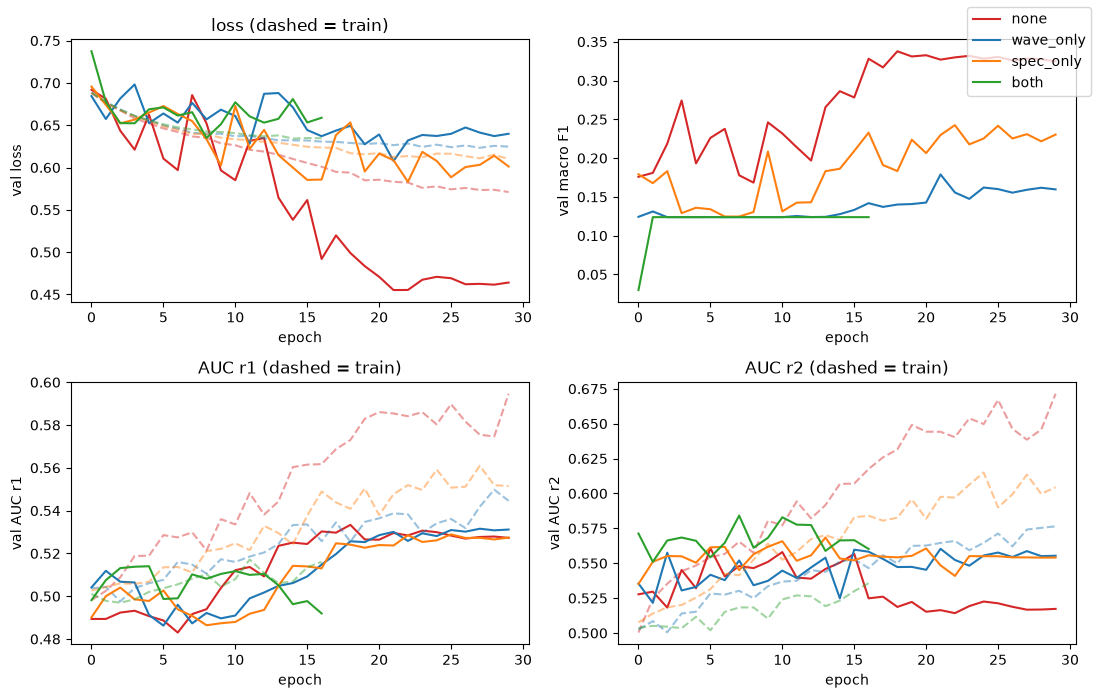

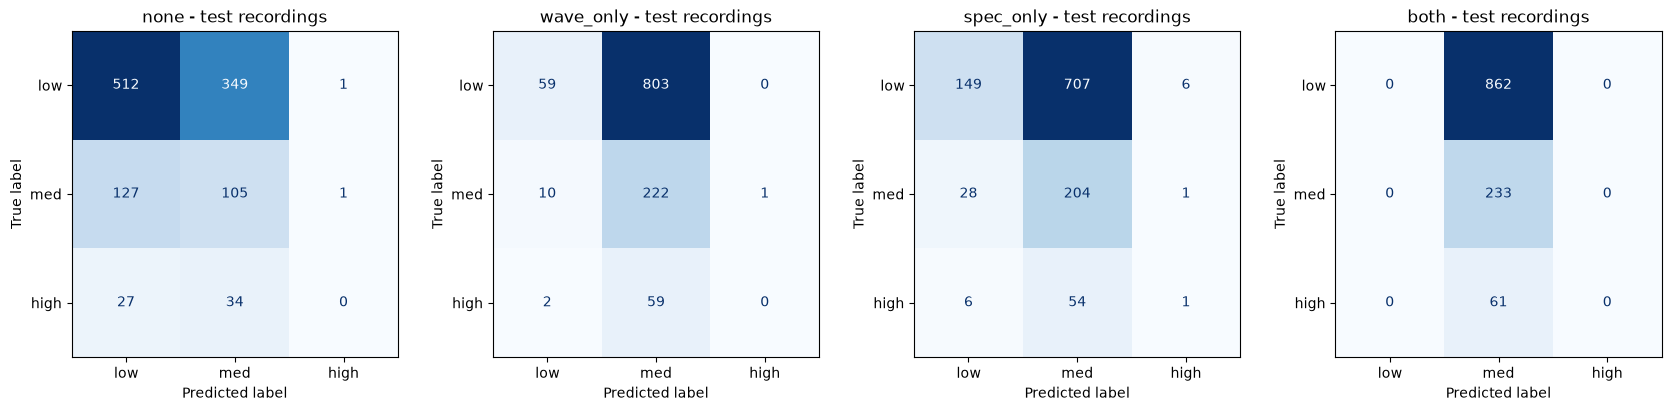

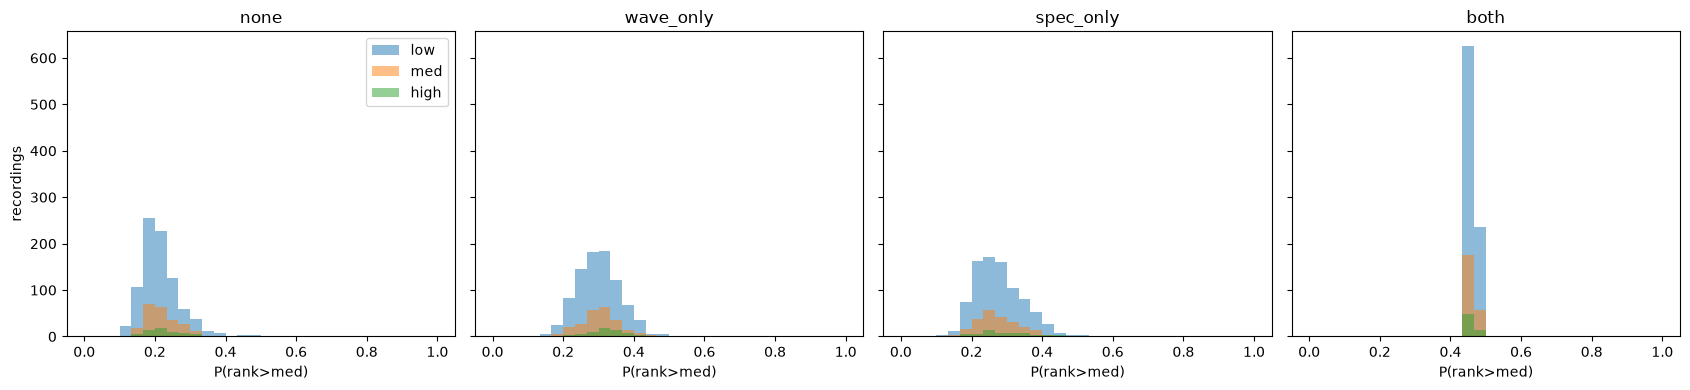

aug figures written to figures_3class/


In [15]:
# ---- Figures: aug experiment (training curves, test CMs, P(rank>med) by true rank) ----
# fresh-kernel recovery: load test state stashed by the test-eval cell
if "aug_test_rec" not in globals() or not aug_test_rec:
    _st = torch.load("run_state_3class/a2_test_state.pt", weights_only=False)
    aug_test_rec = _st["rec"]
    print("=> aug test state restored from run_state_3class/a2_test_state.pt")

_AUG_COLORS: dict[str, str] = {"none": "tab:red", "wave_only": "tab:blue", "spec_only": "tab:orange", "both": "tab:green"}
_AUG_RANK_NAMES: list[str] = ["low", "med", "high"]

# training curves: 2x2 panels, one line per config (train dashed on loss + AUC panels)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
panels = [("val_loss", "val loss"), ("val_F1", "val macro F1"),
          ("val_auc_r1", "val AUC r1"), ("val_auc_r2", "val AUC r2")]
for cfg in AUG_CONFIGS:
    df = pl.read_csv(f"tables_3class/a2__{cfg}__default_experiment_stats.csv")
    for ax, (col, title) in zip(axes.flat, panels):
        ax.plot(df[col].to_list(), label=cfg, color=_AUG_COLORS[cfg])
    axes.flat[0].plot(df["train_loss"].to_list(), color=_AUG_COLORS[cfg], ls="--", alpha=0.45)
    if "train_auc_r1" in df.columns:  # checkpoints predating train_auc have nan columns
        axes.flat[2].plot(df["train_auc_r1"].to_list(), color=_AUG_COLORS[cfg], ls="--", alpha=0.45)
        axes.flat[3].plot(df["train_auc_r2"].to_list(), color=_AUG_COLORS[cfg], ls="--", alpha=0.45)
axes.flat[0].set_title("loss (dashed = train)")
if "train_auc_r1" in df.columns:
    axes.flat[2].set_title("AUC r1 (dashed = train)")
    axes.flat[3].set_title("AUC r2 (dashed = train)")
for i, ax in enumerate(axes.flat):
    ax.set_ylabel(panels[i][1])
    ax.set_xlabel("epoch")
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="upper right")
fig.tight_layout()
fig.savefig("figures_3class/a2_default_curves.png", dpi=200)
plt.show(fig); plt.close(fig)

# test confusion matrices (recording level, counts)
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, cfg in zip(axes, AUG_CONFIGS):
    rec = aug_test_rec[cfg]
    cm = confusion_matrix(rec["true"], rec["pred"], labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=_AUG_RANK_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{cfg} - test recordings")
fig.tight_layout()
fig.savefig("figures_3class/a2_default_test_cm.png", dpi=200)
plt.show(fig); plt.close("all")

# P(rank>med) per recording by true rank (the honest signal picture)
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for ax, cfg in zip(axes, AUG_CONFIGS):
    rec = aug_test_rec[cfg]
    for r in range(3):
        ax.hist(rec["p2"][rec["true"] == r], bins=30, alpha=0.5, range=(0, 1), label=_AUG_RANK_NAMES[r])
    ax.set_title(cfg); ax.set_xlabel("P(rank>med)")
axes[0].set_ylabel("recordings"); axes[0].legend()
fig.tight_layout()
fig.savefig("figures_3class/a2_default_p2_hist.png", dpi=200)
plt.show(fig); plt.close(fig)
print("aug figures written to figures_3class/")

In [13]:
# ---- 5-fold CV: ordinal models, pooled OOF recording-level metrics ----
# Every pool recording is validated exactly once across the folds. Each fold's
# best-val-loss checkpoint feeds pooled out-of-fold segment probabilities, which
# are averaged per RECORDING before any metric is computed (segment-level
# numbers are never the headline). Logs append to logs_3class/ordinal_cv_experiment.txt.
import sys, time, atexit
from datetime import datetime
from zoneinfo import ZoneInfo

LOG_PATH_CV = r"logs_3class/ordinal_cv_experiment.txt"
_logf_cv = open(LOG_PATH_CV, "w", encoding="utf-8")
sys.stdout = _logf_cv
sys.stderr = _logf_cv
atexit.register(_logf_cv.close)

print(f"\n\n\n TIME OF RUN: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}")

HIST_COLS: list[str] = ["train_loss", "train_acc", "train_F1", "train_auc_r1", "train_auc_r2",
                        "val_loss", "val_acc", "val_F1", "val_auc_r1", "val_auc_r2"]

oof_all: dict[str, dict[str, np.ndarray]] = {}  # model -> pooled per-segment OOF across folds
cv_rows: list[dict] = []
_orig = (train_subset, val_subset)
try:
    for mn in CV_MODELS:
        seg_acc: dict[str, list] = {"path": [], "true_rank": [], "p1": [], "p2": [], "fold": []}
        for fi, (tr_pos, va_pos) in enumerate(FOLDS):
            train_subset = Subset(dataset, [cv_pool[p] for p in tr_pos])
            val_subset = Subset(dataset, [cv_pool[p] for p in va_pos])
            key = f"cv__{mn}__f{fi}"
            print(f"\n=== fold {fi + 1}/{len(FOLDS)}  {mn} ===")
            t0 = time.time()
            hist, oof = train_ordinal(
                num_epochs=100, patience=10, name=key, model_name=mn, 
                wave_aug=False, spec_aug=False, mixup_alpha=0.25, balanced_sampler=True
            )
            best_ep = int(np.argmin(hist["val_loss"]))
            cv_rows.append({
                "model": mn, "fold": fi, "epochs": len(hist["val_loss"]),
                "val_loss": round(hist["val_loss"][best_ep], 4),
                "val_acc": round(hist["val_acc"][best_ep], 4),
                "val_F1": round(hist["val_F1"][best_ep], 4),
                "train_auc_r1": round(hist["train_auc_r1"][best_ep], 4),
                "train_auc_r2": round(hist["train_auc_r2"][best_ep], 4),
                "val_auc_r1": round(hist["val_auc_r1"][best_ep], 4),
                "val_auc_r2": round(hist["val_auc_r2"][best_ep], 4),
            })
            print(f"=> {key}: best val_loss {hist['val_loss'][best_ep]:.4f} @ epoch {best_ep + 1} ({time.time() - t0:.0f}s)")
            seg_acc["path"].extend(oof["path"])
            seg_acc["true_rank"].extend(oof["true_rank"])
            seg_acc["p1"].extend(oof["p1"])
            seg_acc["p2"].extend(oof["p2"])
            seg_acc["fold"].extend([fi] * len(oof["p1"]))
            pl.DataFrame({k: hist[k] for k in HIST_COLS}).write_csv(f"tables_3class/cv__{mn}__f{fi}_experiment_stats.csv")
        oof_all[mn] = {k: np.asarray(v) for k, v in seg_acc.items()}
finally:
    train_subset, val_subset = _orig

# persist OOF state so eval/figures survive a fresh kernel
def _save_oof_state(obj: dict) -> None:
    tmp = "run_state_3class/ordinal_oof_state.pt.tmp"
    torch.save(obj, tmp)
    os.replace(tmp, "run_state_3class/ordinal_oof_state.pt")

_save_oof_state({"oof_all": oof_all, "cv_rows": cv_rows})
print("=> OOF state saved to run_state_3class/ordinal_oof_state.pt")
pl.DataFrame(cv_rows).write_csv("tables_3class/cv_ordinal_folds.csv")
print("=> wrote cv_ordinal_folds.csv")

[cv__default__f0] train 1/100:   0%|          | 0/154 [00:00<?, ?it/s]

[cv__default__f0] val 1/100:   0%|          | 0/39 [00:00<?, ?it/s]

[cv__default__f0] train 2/100:   0%|          | 0/154 [00:00<?, ?it/s]

[cv__default__f0] val 2/100:   0%|          | 0/39 [00:00<?, ?it/s]

[cv__default__f0] train 3/100:   0%|          | 0/154 [00:00<?, ?it/s]

[cv__default__f0] val 3/100:   0%|          | 0/39 [00:00<?, ?it/s]

... (1,091 outputs left out)

[cv__resnet__f4] val 37/100:   0%|          | 0/39 [00:00<?, ?it/s]

[cv__resnet__f4] train 38/100:   0%|          | 0/154 [00:00<?, ?it/s]

[cv__resnet__f4] val 38/100:   0%|          | 0/39 [00:00<?, ?it/s]

[cv__resnet__f4] oof:   0%|          | 0/39 [00:00<?, ?it/s]

In [98]:
BATCH_SIZE

128

In [99]:
len(train_subset)

21769

In [101]:
import glob, re, os
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset

STATE_PATH = "run_state_3class/ordinal_oof_state.pt"
HIST_COLS: list[str] = ["train_loss", "train_acc", "train_F1", "train_auc_r1", "train_auc_r2",
                        "val_loss", "val_acc", "val_F1", "val_auc_r1", "val_auc_r2"]
_EXPECTED_SEGS = len(cv_pool)

def _strip_prefix(sd: dict) -> dict:
    return {k.removeprefix("_orig_mod."): v for k, v in sd.items()}

def _feats_cv(waveforms, raw, mel, use_sep: bool):
    waveforms = trim_tile(waveforms)
    feats = mel(waveforms, raw)
    if use_sep:
        spec, mfcc = feats
        if spec.ndim == 3:
            spec, mfcc = spec.unsqueeze(0), mfcc.unsqueeze(0)
        return spec, mfcc
    if feats.ndim == 3:
        feats = feats.unsqueeze(0)
    return feats

def _discover_from_csv() -> dict[str, dict[int, str]]:
    """model -> {fold: csv path}, from the per-fold stats files on disk."""
    pat = re.compile(r"cv__(.+?)__f(\d+)_experiment_stats\.csv$")
    found: dict[str, dict[int, str]] = {}
    for p in sorted(glob.glob("tables_3class/cv__*__f*_experiment_stats.csv")):
        m = pat.search(os.path.basename(p))
        if not m:
            continue
        found.setdefault(m.group(1), {})[int(m.group(2))] = p
    return found

def _cv_rows_from(csv_map: dict[str, dict[int, str]]) -> list[dict]:
    rows: list[dict] = []
    for mn, folds in csv_map.items():
        if mn not in CV_MODELS:
            continue
        for fi, csv in sorted(folds.items()):
            df = pl.read_csv(csv)
            if not len(df):
                continue
            h = {k: df[k].to_list() for k in HIST_COLS}
            ep = int(np.argmin(h["val_loss"]))
            rows.append({"model": mn, "fold": fi, "epochs": len(h["val_loss"]),
                         "val_loss": round(h["val_loss"][ep], 4),
                         "val_acc": round(h["val_acc"][ep], 4),
                         "val_F1": round(h["val_F1"][ep], 4),
                         "train_auc_r1": round(h["train_auc_r1"][ep], 4),
                         "train_auc_r2": round(h["train_auc_r2"][ep], 4),
                         "val_auc_r1": round(h["val_auc_r1"][ep], 4),
                         "val_auc_r2": round(h["val_auc_r2"][ep], 4)})
    return rows

def _rebuild_oof_from_csv(mn: str, folds: dict[int, str]) -> dict[str, np.ndarray]:
    """Probabilities come from each fold's saved _best checkpoint."""
    seg: dict[str, list] = {"path": [], "true_rank": [], "p1": [], "p2": [], "fold": []}
    use_sep = (mn == "branched")
    for fi, csv in sorted(folds.items()):
        key = f"cv__{mn}__f{fi}"
        cp = _ckpt_best_path(key) if os.path.exists(_ckpt_best_path(key)) else _ckpt_path(key)
        if not os.path.exists(cp):
            raise FileNotFoundError(f"missing checkpoint for {key}")
        st = torch.load(cp, weights_only=True, map_location=device)
        model = CoralOrdinal(_make_model(mn, num_classes=1)).to(device)
        model.load_state_dict(_strip_prefix(st["model_state_dict"]))
        model.eval()
        _, va_pos = FOLDS[fi]
        idxs = [int(cv_pool[p]) for p in va_pos]
        loader = DataLoader(Subset(dataset, idxs), BATCH_SIZE, shuffle=False,
                            num_workers=0, pin_memory=True)
        p1s, p2s = [], []
        with torch.inference_mode():
            for waveforms, labels in tqdm(loader, desc=f"[repair {mn} f{fi}]", leave=False):
                waveforms = waveforms.to(device, non_blocking=True)
                raw = labels.long().to(device)
                feats = _feats_cv(waveforms, raw, mel_eval_sep if use_sep else mel_eval, use_sep)
                probs = torch.sigmoid(model(feats).float())
                p1s.append(probs[:, 0].cpu().numpy())
                p2s.append(probs[:, 1].cpu().numpy())
        seg["path"].extend([dataset.get_path(i) for i in idxs])
        seg["true_rank"].extend([RANK[int(dataset.labels[i])] for i in idxs])
        seg["p1"].extend(np.concatenate(p1s))
        seg["p2"].extend(np.concatenate(p2s))
        seg["fold"].extend([fi] * len(idxs))
        del model
        torch.cuda.empty_cache() if device.type == "cuda" else None
    return {k: np.asarray(v) for k, v in seg.items()}

# --- load existing state, then merge ---
oof_all: dict[str, dict[str, np.ndarray]] = {}
cv_rows: list[dict] = []
if os.path.exists(STATE_PATH):
    _st = torch.load(STATE_PATH, weights_only=False)
    oof_all = dict(_st.get("oof_all", {}))
    cv_rows = list(_st.get("cv_rows", []))
    print(f"=> loaded state: {sorted(oof_all)}")

csv_map = _discover_from_csv()
print("=> CSVs found:", {mn: sorted(folds) for mn, folds in csv_map.items()})

for mn in CV_MODELS:
    if mn not in csv_map:
        continue
    if mn not in oof_all or len(oof_all[mn].get("p1", [])) != _EXPECTED_SEGS:
        print(f"=> rebuilding OOF for {mn} from {len(csv_map[mn])} fold checkpoints")
        oof_all[mn] = _rebuild_oof_from_csv(mn, csv_map[mn])
    else:
        print(f"=> {mn}: OOF already complete ({len(oof_all[mn]['p1'])} segments)")

oof_all = {mn: oof_all[mn] for mn in CV_MODELS if mn in oof_all}
cv_rows = _cv_rows_from(csv_map)

missing = [mn for mn in CV_MODELS if mn not in oof_all or
           len(oof_all[mn]["p1"]) != _EXPECTED_SEGS]
assert not missing, f"incomplete OOF (expected {_EXPECTED_SEGS} segs/model): {missing}"
print(f"=> OOF state covers: {sorted(oof_all)}; {_EXPECTED_SEGS} segments per model")

_tmp = STATE_PATH + ".tmp"
torch.save({"oof_all": oof_all, "cv_rows": cv_rows}, _tmp)
os.replace(_tmp, STATE_PATH)
pl.DataFrame(cv_rows).write_csv("tables_3class/cv_ordinal_folds.csv")
print("=> ordinal_oof_state.pt + cv_ordinal_folds.csv rewritten")

[repair default f0]:   0%|          | 0/39 [00:00<?, ?it/s]

[repair default f1]:   0%|          | 0/39 [00:00<?, ?it/s]

[repair default f2]:   0%|          | 0/39 [00:00<?, ?it/s]

[repair default f3]:   0%|          | 0/39 [00:00<?, ?it/s]

[repair default f4]:   0%|          | 0/39 [00:00<?, ?it/s]

[repair branched f0]:   0%|          | 0/39 [00:00<?, ?it/s]

[repair branched f1]:   0%|          | 0/39 [00:00<?, ?it/s]

[repair branched f2]:   0%|          | 0/39 [00:00<?, ?it/s]

[repair branched f3]:   0%|          | 0/39 [00:00<?, ?it/s]

[repair branched f4]:   0%|          | 0/39 [00:00<?, ?it/s]

In [14]:
# ---- Recording-level OOF eval per model (the headline numbers) ----
# fresh-kernel recovery: load OOF state persisted by the CV cell
if "oof_all" not in globals() or not oof_all:
    _st = torch.load("run_state_3class/ordinal_oof_state.pt", weights_only=False)
    oof_all, cv_rows = _st["oof_all"], _st["cv_rows"]
    print("=> OOF state restored from run_state_3class/ordinal_oof_state.pt")

# aggregate_recordings lives in the helpers cell (shared with the aug test cell)
EVAL_COLS: list[str] = ["model", "n_recordings", "macro_f1", "recall_low", "recall_med", "recall_high",
                        "auc_r1", "auc_r2", "macro_auc", "rank_mae"]
eval_rows: list[dict] = []
rec_level: dict[str, dict[str, np.ndarray]] = {}
for mn in CV_MODELS:
    rec = aggregate_recordings(oof_all[mn])
    rec_level[mn] = rec
    m = ordinal_oof_metrics(rec["true"], rec["pred"], rec["p1"], rec["p2"])
    eval_rows.append({"model": mn, "n_recordings": len(rec["true"]),
                      **{k: (round(v, 4) if v is not None else None) for k, v in m.items()}})
    cm = confusion_matrix(rec["true"], rec["pred"], labels=[0, 1, 2])
    print(f"\n=== OOF recording-level [{mn}] ({len(rec['true'])} recordings) ===")
    print(f"(rows=true ['low','med','high'], cols=pred)\n{cm}")
    print({k: m[k] for k in m})
pl.DataFrame(eval_rows).write_csv("tables_3class/ordinal_oof_eval.csv")
print("=> wrote ordinal_oof_eval.csv")


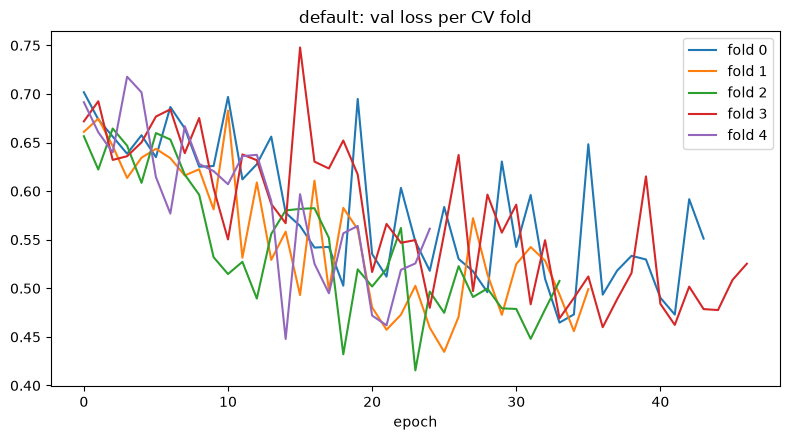

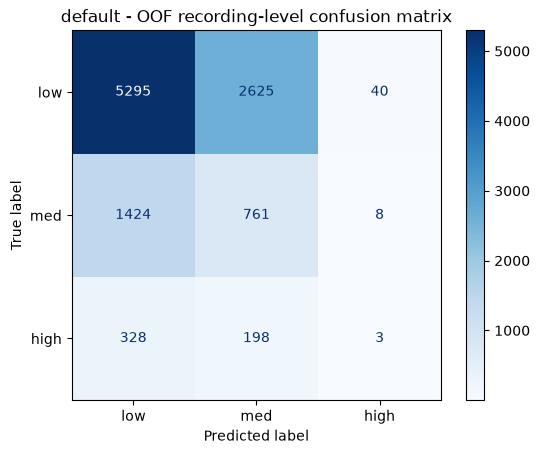

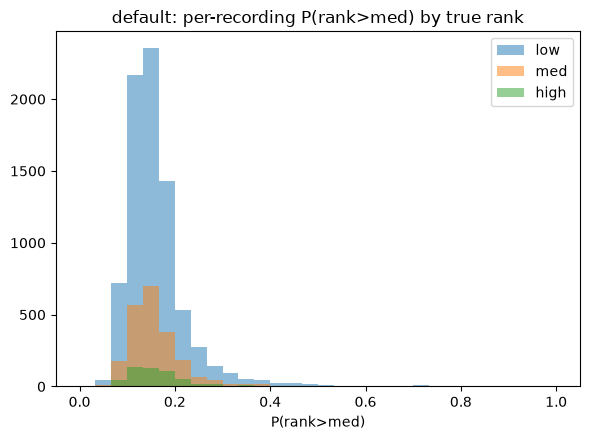

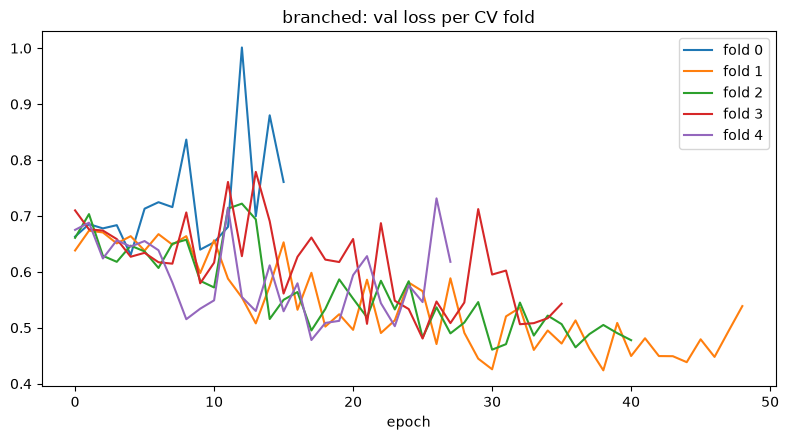

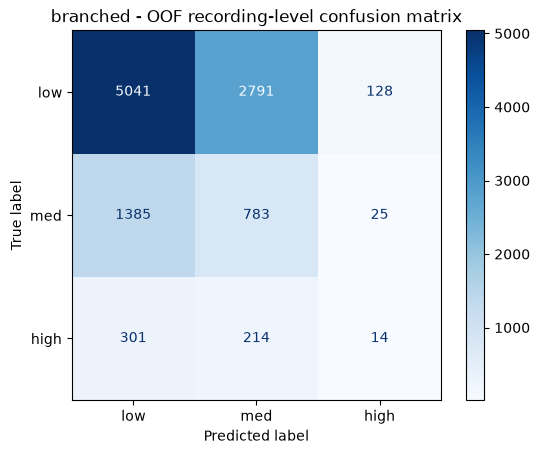

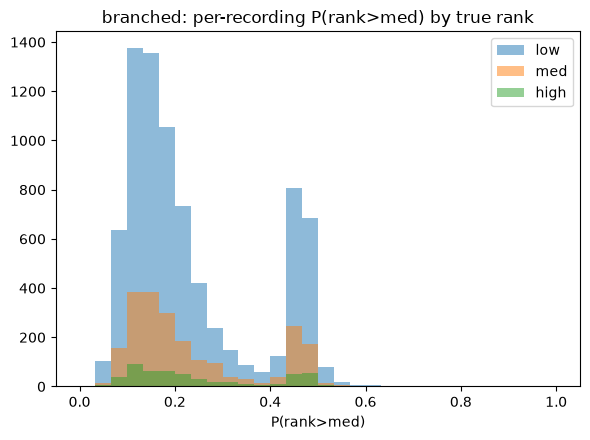

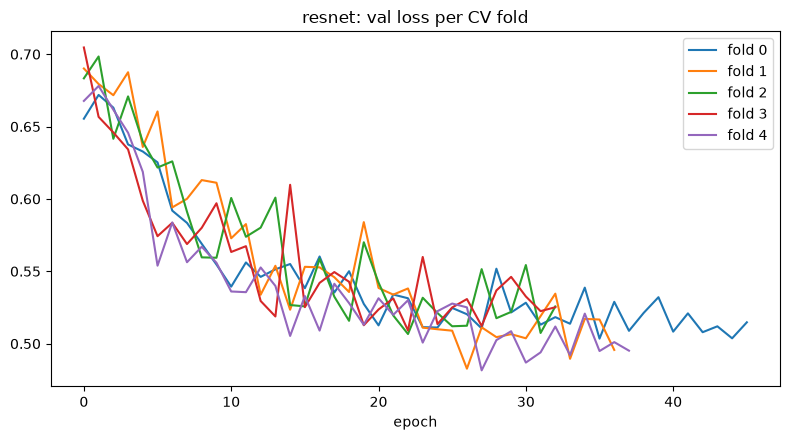

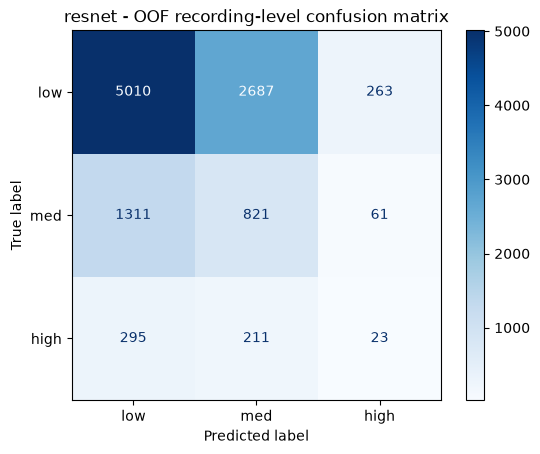

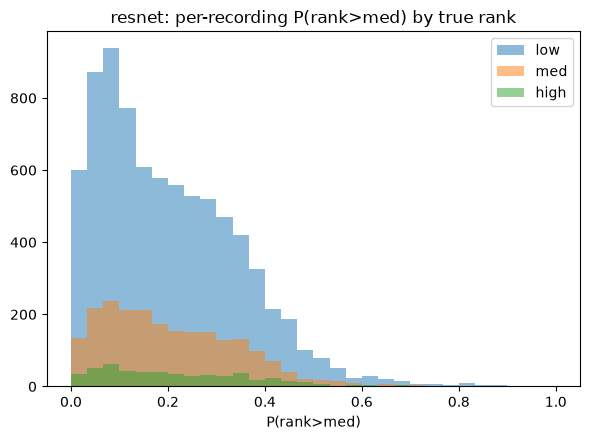

In [17]:
# ---- Figures: per-fold histories, ordinal CMs, P(risk>med) distributions ----
os.makedirs("figures_3class", exist_ok=True)
RANK_NAMES: list[str] = ["low", "med", "high"]

for mn in CV_MODELS:
    # history: one val-loss line per fold
    fig, ax = plt.subplots(figsize=(8, 4.5))
    plotted = False
    for fi in range(N_FOLDS):
        csv = f"tables_3class/cv__{mn}__f{fi}_experiment_stats.csv"
        if os.path.exists(csv):
            df = pl.read_csv(csv)
            ax.plot(df["val_loss"].to_list(), label=f"fold {fi}")
            plotted = True
    if plotted:
        ax.set_title(f"{mn}: val loss per CV fold"); ax.set_xlabel("epoch"); ax.legend()
        fig.tight_layout(); fig.savefig(f"figures_3class/ordinal_{mn}_history.png", dpi=200)
        plt.show(fig); plt.close(fig)

    # ordinal confusion matrix (recording level)
    rec = rec_level[mn]
    cm = confusion_matrix(rec["true"], rec["pred"], labels=[0, 1, 2])
    disp = ConfusionMatrixDisplay(cm, display_labels=RANK_NAMES)
    disp.plot(cmap="Blues")
    plt.title(f"{mn} - OOF recording-level confusion matrix")
    plt.savefig(f"figures_3class/ordinal_{mn}_cm.png", bbox_inches="tight", dpi=200)
    plt.show(); plt.close("all")

    # honest signal picture: per-recording P(rank>med) by true rank
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for r in range(3):
        ax.hist(rec["p2"][rec["true"] == r], bins=30, alpha=0.5, label=RANK_NAMES[r], range=(0, 1))
    ax.set_title(f"{mn}: per-recording P(rank>med) by true rank"); ax.set_xlabel("P(rank>med)"); ax.legend()
    fig.tight_layout(); fig.savefig(f"figures_3class/ordinal_{mn}_p2_hist.png", dpi=200)
    plt.show(fig); plt.close(fig)
print("figures written to figures_3class/")


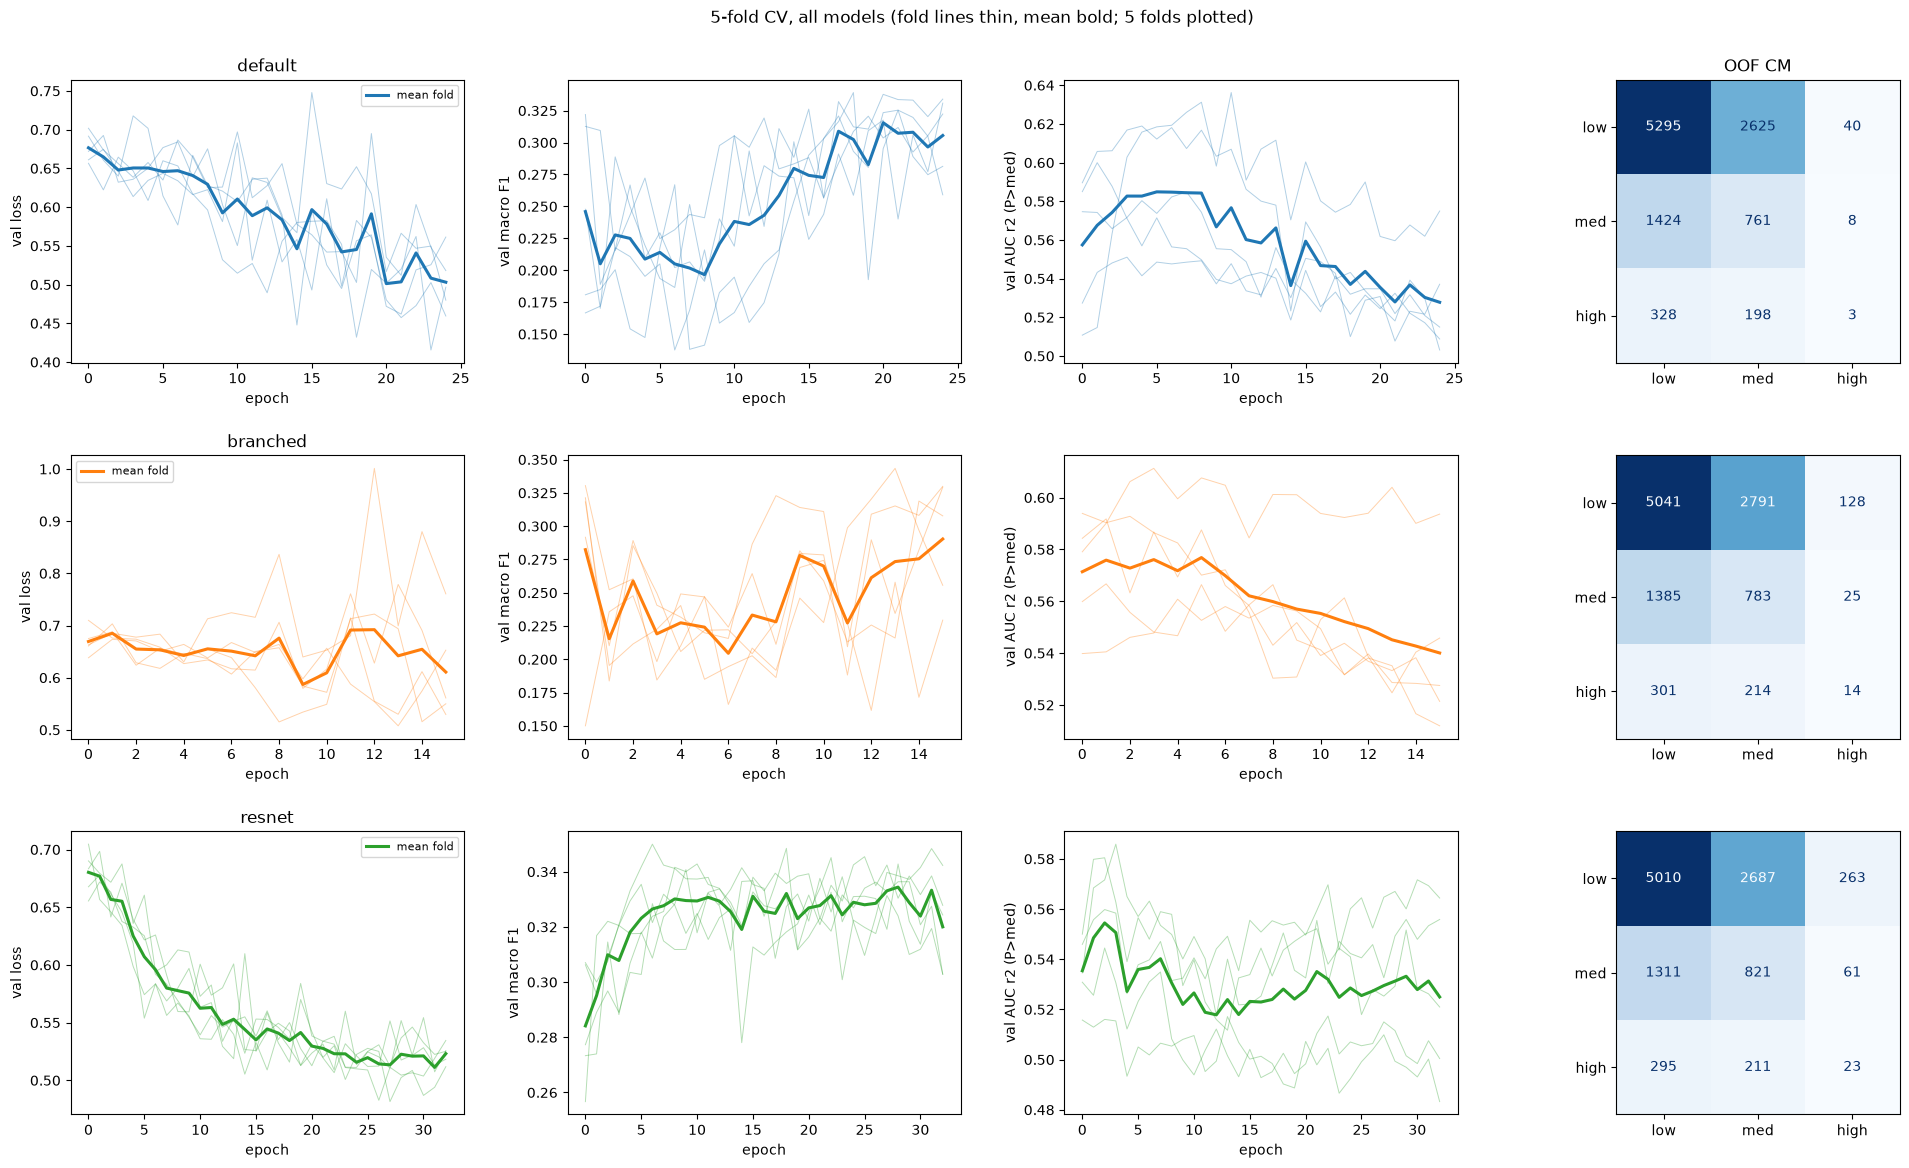

In [18]:
if "rec_level" not in globals() or not rec_level:
    _st = torch.load("run_state_3class/ordinal_oof_state.pt", weights_only=False)
    oof_all, cv_rows = _st["oof_all"], _st["cv_rows"]
    rec_level = {mn: aggregate_recordings(oof_all[mn]) for mn in CV_MODELS}
    print("=> OOF state restored from run_state_3class/ordinal_oof_state.pt")

CV_RANK_NAMES: list[str] = ["low", "med", "high"]
_MODEL_COLORS: list[str] = ["tab:blue", "tab:orange", "tab:green"]

fig, axes = plt.subplots(3, 4, figsize=(20, 12))

for row, (mn, color) in enumerate(zip(CV_MODELS, _MODEL_COLORS)):
    ax_loss, ax_f1, ax_auc, ax_cm = axes[row]

    # collect per-fold histories (fresh-kernel safe: read the CSVs)
    folds: list[pl.DataFrame] = []
    for fi in range(N_FOLDS):
        csv = f"tables_3class/cv__{mn}__f{fi}_experiment_stats.csv"
        if os.path.exists(csv):
            folds.append(pl.read_csv(csv))
    if folds:
        # align by epoch index: folds early-stop at different lengths
        min_len = min(len(df) for df in folds)
        for col, ax, label in [("val_loss", ax_loss, "val loss"),
                               ("val_F1", ax_f1, "val macro F1"),
                               ("val_auc_r2", ax_auc, "val AUC r2 (P>med)")]:
            vals = np.stack([df[col].to_list()[:min_len] for df in folds])
            for v in vals:
                ax.plot(v, lw=0.7, alpha=0.35, color=color)   # individual folds
            ax.plot(vals.mean(axis=0), lw=2.2, color=color, label="mean fold")
            ax.set_ylabel(label); ax.set_xlabel("epoch")
        n_discrete = len(folds)
    else:
        for ax in (ax_loss, ax_f1, ax_auc):
            ax.text(0.5, 0.5, "no fold CSVs found", ha="center", va="center", transform=ax.transAxes)
        n_discrete = 0

    ax_loss.set_title(f"{mn}")
    ax_loss.legend(fontsize=8)

    # OOF recording-level confusion matrix
    rec = rec_level[mn]
    cm = confusion_matrix(rec["true"], rec["pred"], labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=CV_RANK_NAMES).plot(
        ax=ax_cm, cmap="Blues", colorbar=False)
    ax_cm.set_title("OOF CM" if row == 0 else "")
    ax_cm.set_xlabel(""); ax_cm.set_ylabel("")

fig.suptitle(f"5-fold CV, all models (fold lines thin, mean bold; {n_discrete} folds plotted)", y=0.98)
fig.tight_layout(pad=2)
fig.savefig("figures_3class/cv_combined_models.png", dpi=200, bbox_inches="tight")
plt.show(fig); plt.close(fig)
print("=> figures_3class/cv_combined_models.png written")

[best default f1] test:   0%|          | 0/22 [00:00<?, ?it/s]

[best branched f0] test:   0%|          | 0/22 [00:00<?, ?it/s]

[best resnet f4] test:   0%|          | 0/22 [00:00<?, ?it/s]

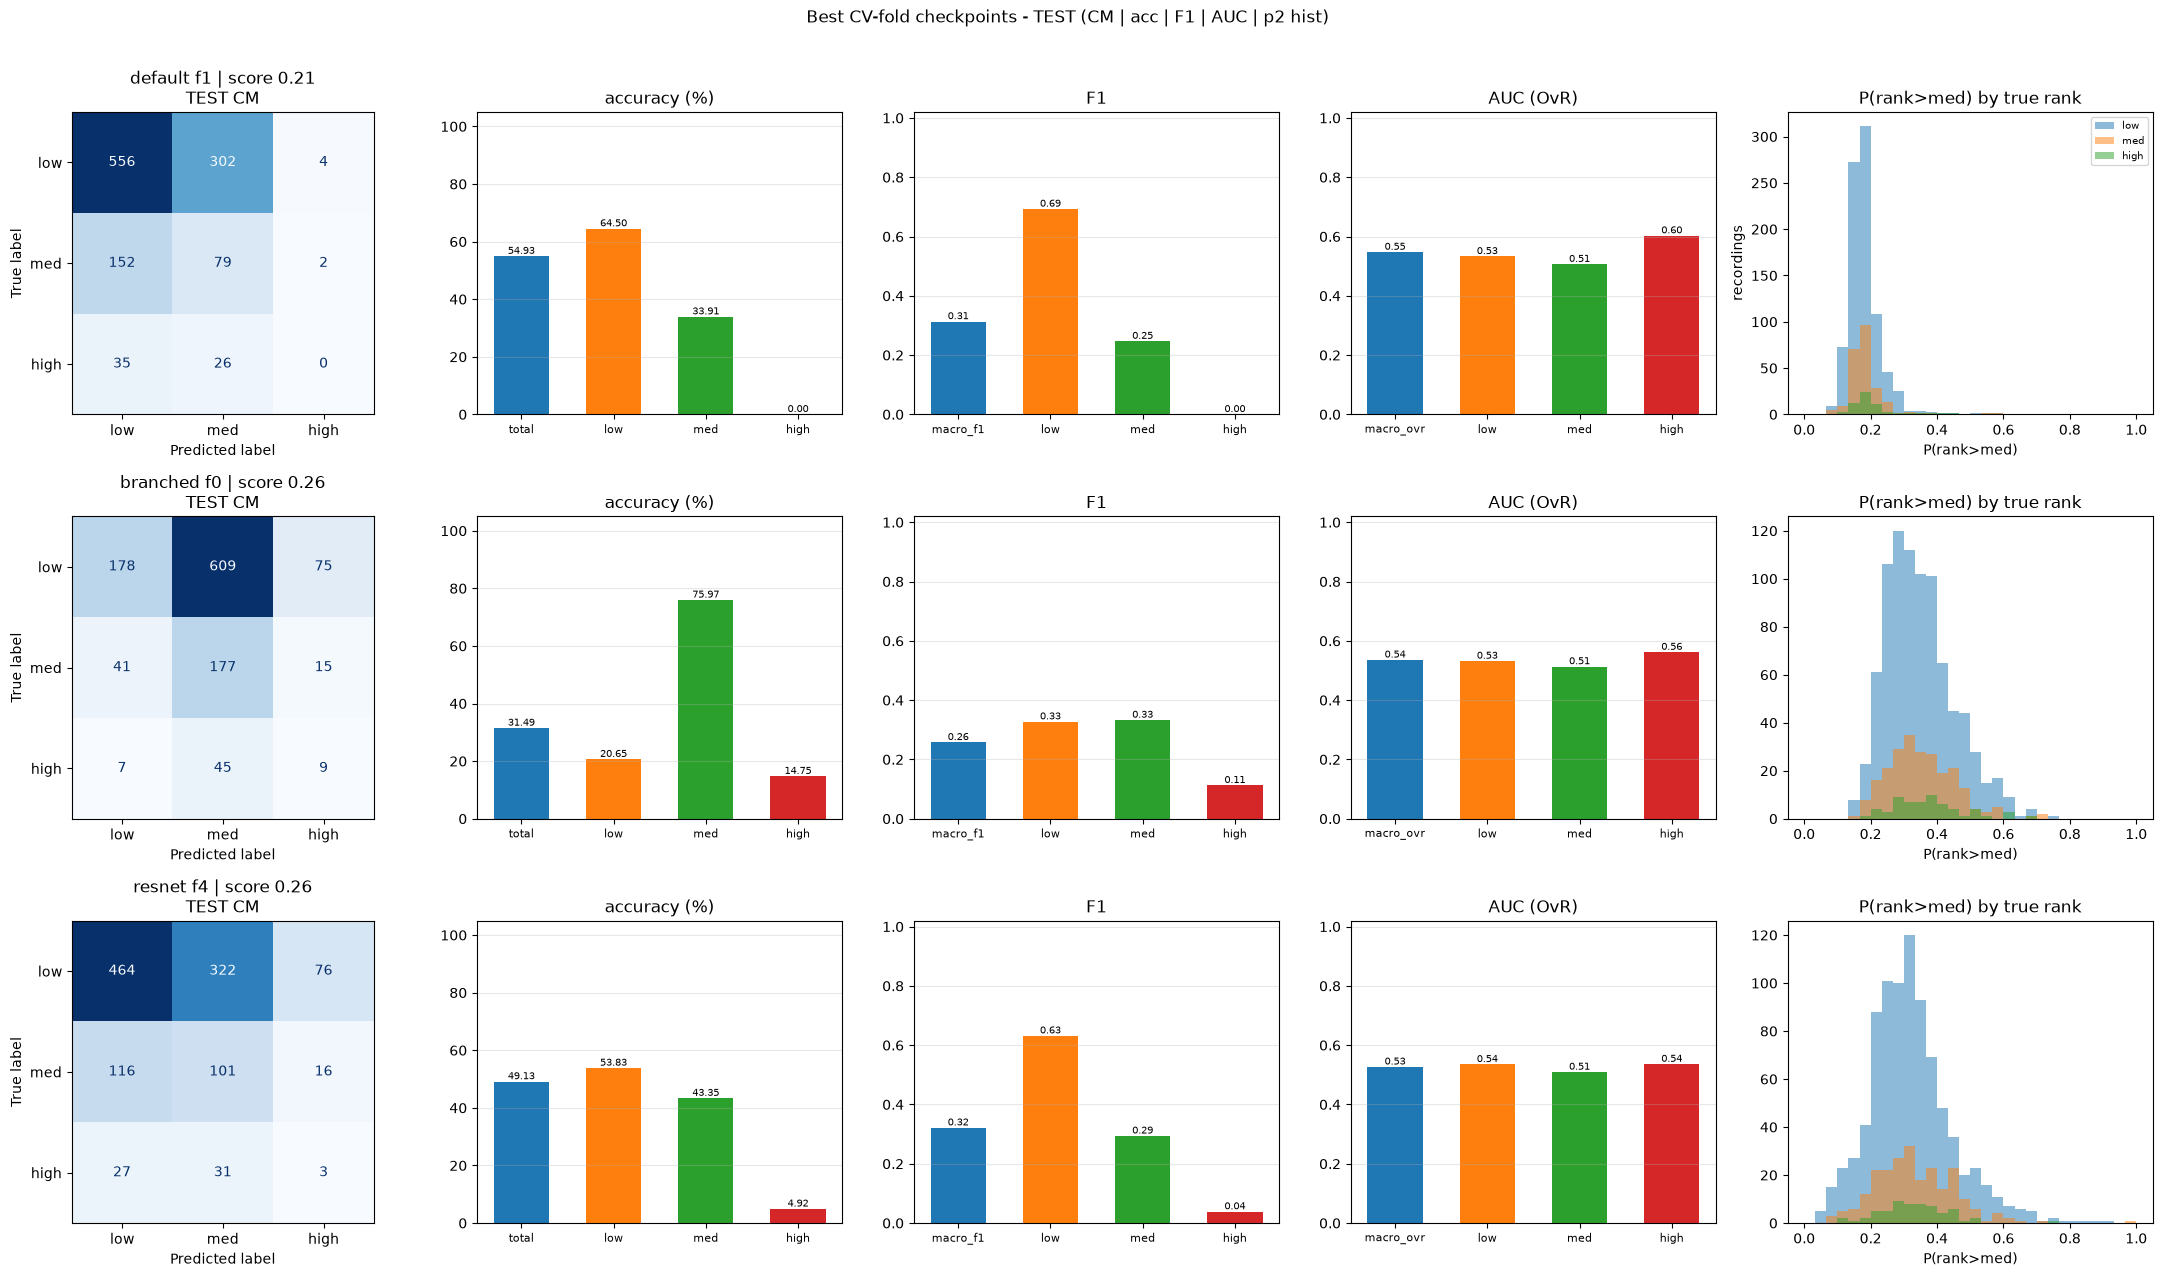

In [41]:
import os
import numpy as np
import polars as pl
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score
from tqdm.auto import tqdm

SEL_CSV = "tables_3class/ensemble_selected_ckpts.csv"
OUT_CSV = "tables_3class/best_cvfold_test_eval.csv"
RANK_NAMES: list[str] = ["low", "med", "high"]


def _strip_prefix(sd: dict) -> dict:
    return {k.removeprefix("_orig_mod."): v for k, v in sd.items()}


def _feats_eval(waveforms, raw, mel, use_sep: bool):
    waveforms = trim_tile(waveforms)
    feats = mel(waveforms, raw)
    if use_sep:
        spec, mfcc = feats
        if spec.ndim == 3:
            spec, mfcc = spec.unsqueeze(0), mfcc.unsqueeze(0)
        return spec, mfcc
    if feats.ndim == 3:
        feats = feats.unsqueeze(0)
    return feats


def _extra_metrics(rec: dict, pred: np.ndarray) -> dict:
    t = rec["true"]
    p1, p2 = np.clip(rec["p1"], 0, 1), np.clip(rec["p2"], 0, 1)
    accs = {f"acc_{n}": round(100 * float(np.mean(pred[t == k] == k)), 2)
            for k, n in enumerate(RANK_NAMES)}
    scores = {"low": 1.0 - p1, "med": p1 - p2, "high": p2}
    aucs = {f"auc_{n}": (round(float(roc_auc_score((t == k).astype(int), s)), 4)
                        if len(np.unique(t == k)) > 1 else None)
            for k, (n, s) in enumerate(scores.items())}
    valid = [v for v in aucs.values() if v is not None]
    return {"acc_total": round(100 * float(np.mean(pred == t)), 2), **accs,
            "auc_macro_ovr": round(float(np.mean(valid)), 4) if valid else None, **aucs}


def _metrics(rec: dict) -> dict:
    t, pred = rec["true"], rec["pred"]
    m = ordinal_oof_metrics(t, pred, rec["p1"], rec["p2"])
    f1s = f1_score(t, pred, average=None, labels=[0, 1, 2], zero_division=0)
    out = {k: (round(v, 4) if v is not None else None) for k, v in m.items()}
    out.update({f"f1_{n}": round(float(f1s[k]), 4) for k, n in enumerate(RANK_NAMES)})
    out.update(_extra_metrics(rec, pred))
    return out


# rank-1 checkpoint per model from the val selection CSV
sel = pl.read_csv(SEL_CSV)
_score_col = "score" if "score" in sel.columns else "val_loss"
best_rows: list[dict] = []
for mn in CV_MODELS:
    sub = sel.filter(pl.col("model") == mn).sort("rank")
    if not len(sub):
        print(f"!! no selected checkpoint for {mn}")
        continue
    best_rows.append(sub.row(0, named=True))

test_loader = DataLoader(Subset(dataset, test_subset.indices), BATCH_SIZE,
                         shuffle=False, num_workers=0, pin_memory=True)
test_paths = np.asarray([dataset.get_path(int(i)) for i in test_subset.indices], dtype=object)
true_ranks = np.asarray([RANK[int(dataset.labels[i])] for i in test_subset.indices], dtype=int)

rows: list[dict] = []
recs: dict[str, dict] = {}
for r in best_rows:
    mn, fi, ckpt = r["model"], int(r["fold"]), r["ckpt"]
    cp = os.path.join(RUN_STATE_DIR, ckpt)
    use_sep = (mn == "branched")
    model = CoralOrdinal(_make_model(mn, num_classes=1)).to(device)
    model.load_state_dict(_strip_prefix(
        torch.load(cp, weights_only=True, map_location=device)["model_state_dict"]))
    model.eval()
    p1s, p2s = [], []
    with torch.inference_mode():
        for waveforms, labels in tqdm(test_loader, desc=f"[best {mn} f{fi}] test", leave=False):
            waveforms = waveforms.to(device, non_blocking=True)
            raw = labels.long().to(device)
            feats = _feats_eval(waveforms, raw, mel_eval_sep if use_sep else mel_eval, use_sep)
            probs = torch.sigmoid(model(feats).float())
            p1s.append(probs[:, 0].cpu().numpy())
            p2s.append(probs[:, 1].cpu().numpy())
    rec = aggregate_recordings({"path": test_paths, "true_rank": true_ranks,
                                "p1": np.concatenate(p1s), "p2": np.concatenate(p2s)})
    recs[mn] = rec
    rows.append({"model": mn, "fold": fi, "ckpt": ckpt,
                 "val_score": round(float(r[_score_col]), 4),
                 "n_recordings": len(rec["true"]), **_metrics(rec)})
    del model
    torch.cuda.empty_cache() if device.type == "cuda" else None



pl.DataFrame(rows).write_csv(OUT_CSV)
print("\n=== BEST CV fold per model - TEST (recording level; printed here, not logged) ===")
print(pl.DataFrame(rows))
for r in rows:
    rec = recs[r["model"]]
    cm = confusion_matrix(rec["true"], rec["pred"], labels=[0, 1, 2])
    print(f"\n[{r['model']}] fold {r['fold']}  {r['ckpt']}  val_score={r['val_score']}")
    print("rows=true ['low','med','high'], cols=pred")
    print(cm)
print(f"\n=> wrote {OUT_CSV}")


os.makedirs("figures_3class", exist_ok=True)

_acc_keys = ["acc_total", "acc_low", "acc_med", "acc_high"]
_f1_keys = ["macro_f1", "f1_low", "f1_med", "f1_high"]
_auc_keys = ["auc_macro_ovr", "auc_low", "auc_med", "auc_high"]
_panel_keys = [_acc_keys, _f1_keys, _auc_keys]
_panel_titles = ["accuracy (%)", "F1", "AUC (OvR)"]

fig, axes = plt.subplots(len(rows), 5, figsize=(22, 4.2 * len(rows)))
if len(rows) == 1:
    axes = axes[None, :]

for i, r in enumerate(rows):
    mn = r["model"]
    rec = recs[mn]

    # CM
    cm = confusion_matrix(rec["true"], rec["pred"], labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=RANK_NAMES).plot(
        ax=axes[i, 0], cmap="Blues", colorbar=False)
    _vs = r["val_score"]
    _score_txt = "" if _vs is None else f" | score {_vs:.2f}"
    axes[i, 0].set_title(f"{mn} f{r['fold']}{_score_txt}\nTEST CM")

    # acc / F1 / AUC bars
    for j, (keys, title) in enumerate(zip(_panel_keys, _panel_titles), start=1):
        ax = axes[i, j]
        for k_i, k in enumerate(keys):
            v = r[k]
            ax.bar(k_i, v if v is not None else np.nan, 0.6)
            if v is not None:
                ax.text(k_i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=7)
        ax.set_xticks(range(len(keys)))
        ax.set_xticklabels([k.replace("acc_", "").replace("f1_", "").replace("auc_", "")
                            for k in keys], fontsize=8)
        ax.set_title(title)
        ax.grid(axis="y", alpha=0.3)
        ax.set_ylim(0, 105 if j == 1 else 1.02)

    # P(p2) hist
    ax = axes[i, 4]
    for rank in range(3):
        ax.hist(rec["p2"][rec["true"] == rank], bins=30, alpha=0.5, range=(0, 1),
                label=RANK_NAMES[rank])
    ax.set_title("P(rank>med) by true rank")
    ax.set_xlabel("P(rank>med)")
    if i == 0:
        ax.set_ylabel("recordings")
        ax.legend(fontsize=7)

fig.suptitle("Best CV-fold checkpoints - TEST (CM | acc | F1 | AUC | p2 hist)", y=1.01)
fig.tight_layout()
fig.savefig("figures_3class/best_cvfold_test_giant.png", dpi=150, bbox_inches="tight")
plt.show(fig); plt.close(fig)
print("=> figures_3class/best_cvfold_test_giant.png written")


[best-F1 default f0] test:   0%|          | 0/22 [00:00<?, ?it/s]

[best-F1 branched f1] test:   0%|          | 0/22 [00:00<?, ?it/s]

[best-F1 resnet f4] test:   0%|          | 0/22 [00:00<?, ?it/s]

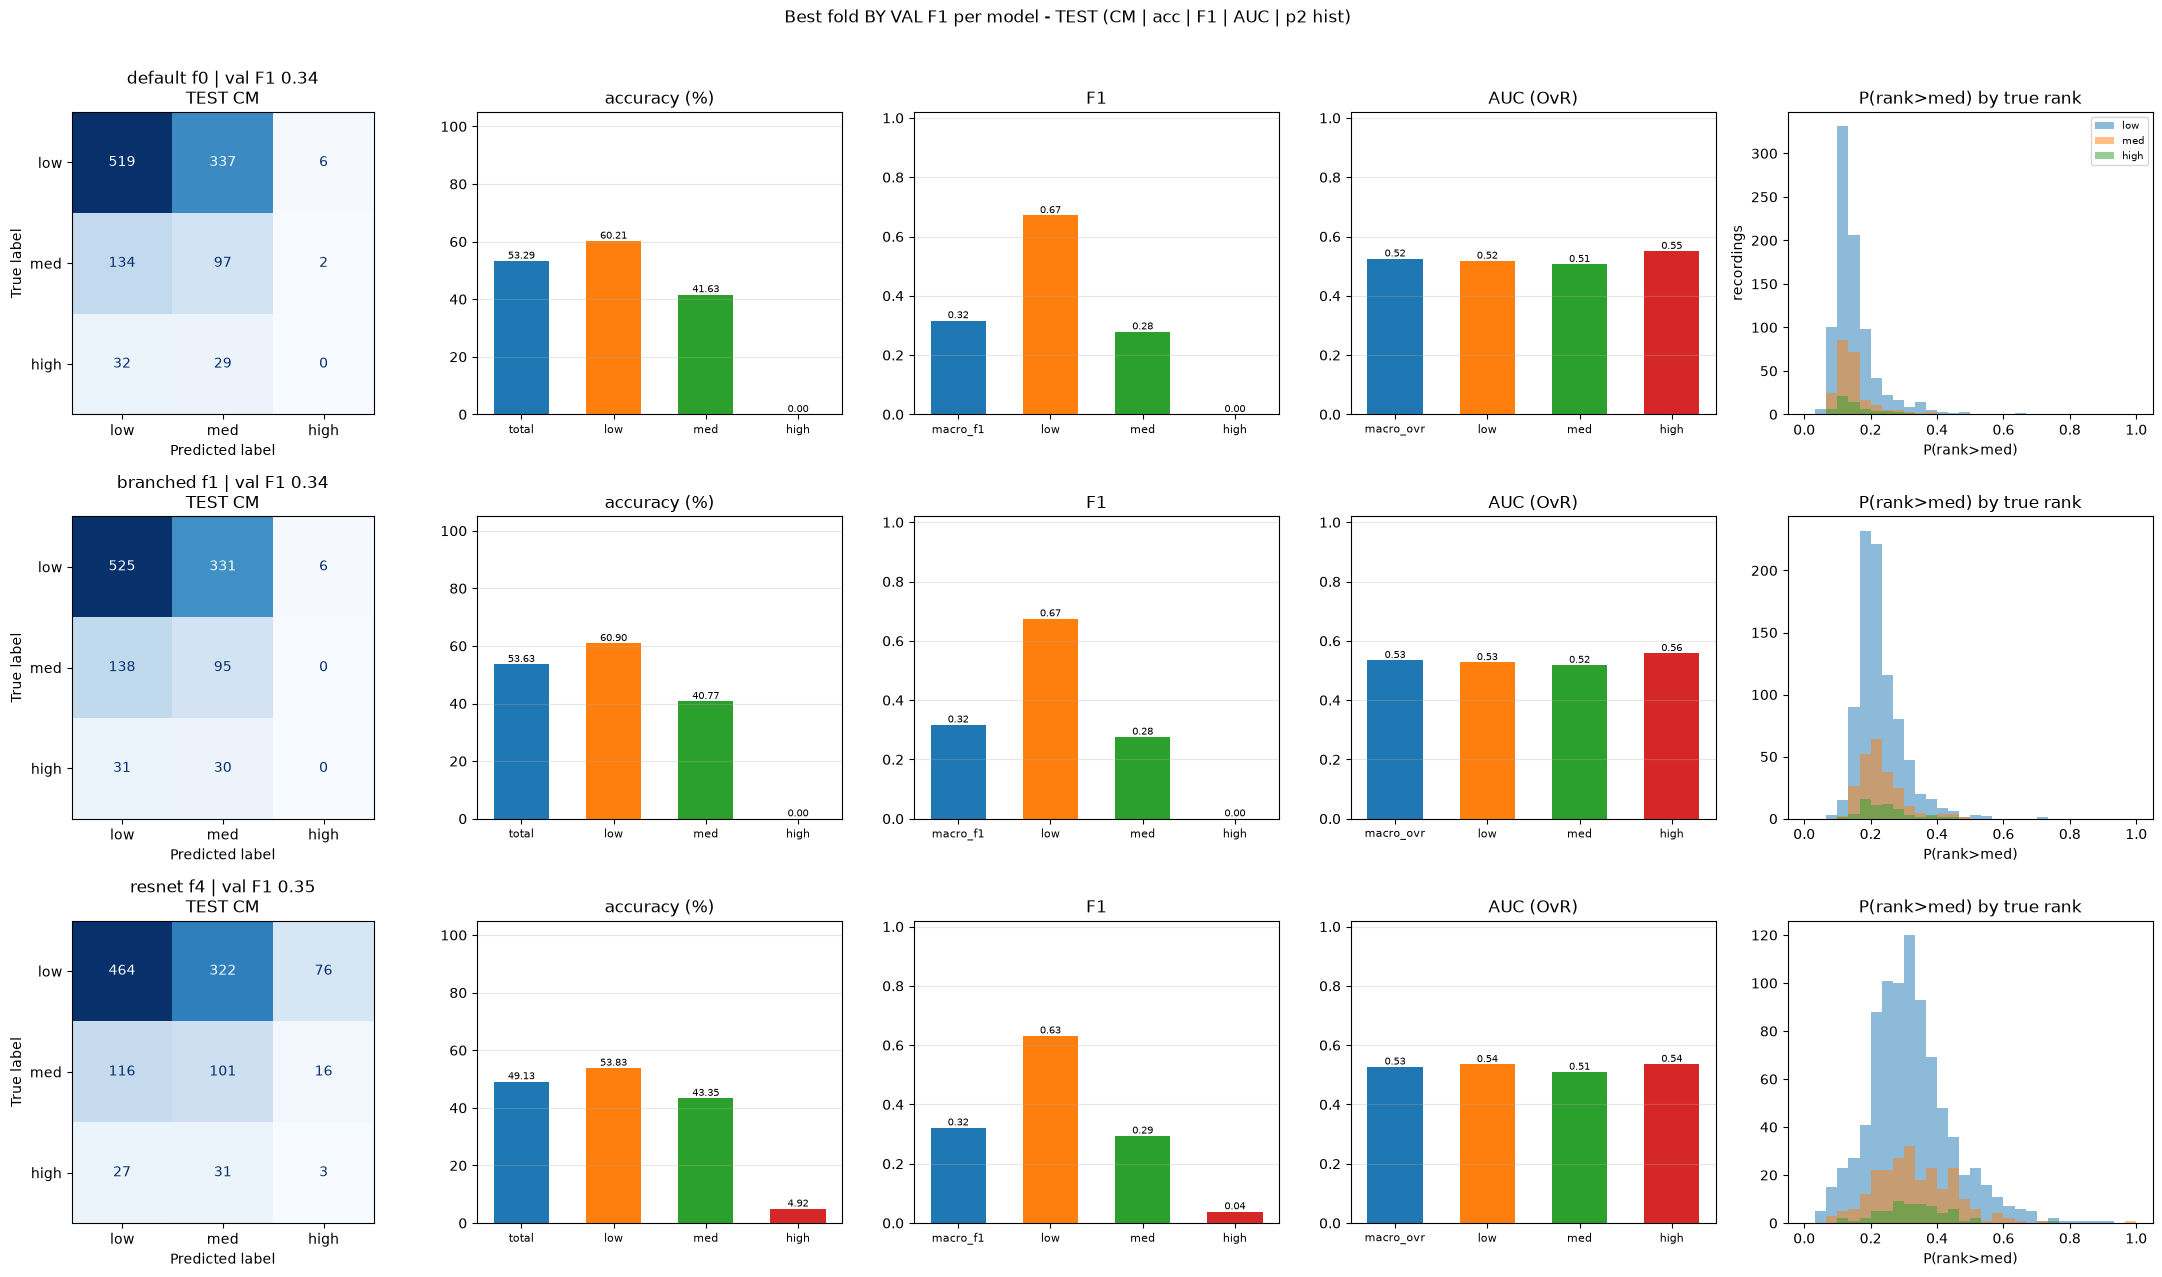

In [40]:
import os, re, glob
import numpy as np
import polars as pl
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import confusion_matrix
from tqdm.auto import tqdm

for _fn in ("_strip_prefix", "_feats_eval", "_metrics"):
    assert _fn in globals(), f"run the previous best-CV-fold cell first (missing {_fn})"

OUT_CSV_F1 = "tables_3class/best_f1_fold_test_eval.csv"
RANK_NAMES: list[str] = ["low", "med", "high"]

# per model: fold with the highest best val_F1; its _best checkpoint IS that model
best_f1: list[dict] = []
for mn in CV_MODELS:
    cands: list[tuple[float, int, str]] = []
    for p in glob.glob(f"tables_3class/cv__{mn}__f*_experiment_stats.csv"):
        m = re.search(rf"cv__{re.escape(mn)}__f(\d+)_experiment_stats\.csv$", os.path.basename(p))
        if not m:
            continue
        df = pl.read_csv(p)
        if "val_F1" not in df.columns or not len(df):
            continue
        vals = [float(x) for x in df["val_F1"].to_list() if x is not None and np.isfinite(x)]
        if vals:
            cands.append((max(vals), int(m.group(1)), p))
    if not cands:
        print(f"!! no val_F1 CSVs for {mn}")
        continue
    f1, fi, _csv = max(cands)
    cp = _ckpt_best_path(f"cv__{mn}__f{fi}")
    if not os.path.exists(cp):
        cp = _ckpt_path(f"cv__{mn}__f{fi}")
    if not os.path.exists(cp):
        print(f"!! no checkpoint for cv__{mn}__f{fi}")
        continue
    best_f1.append({"model": mn, "fold": fi, "val_F1": f1, "path": cp})

test_loader = DataLoader(Subset(dataset, test_subset.indices), BATCH_SIZE,
                         shuffle=False, num_workers=0, pin_memory=True)
test_paths = np.asarray([dataset.get_path(int(i)) for i in test_subset.indices], dtype=object)
true_ranks = np.asarray([RANK[int(dataset.labels[i])] for i in test_subset.indices], dtype=int)

rows: list[dict] = []
recs: dict[str, dict] = {}
for c in best_f1:
    mn, fi, cp = c["model"], c["fold"], c["path"]
    use_sep = (mn == "branched")
    model = CoralOrdinal(_make_model(mn, num_classes=1)).to(device)
    model.load_state_dict(_strip_prefix(
        torch.load(cp, weights_only=True, map_location=device)["model_state_dict"]))
    model.eval()
    p1s, p2s = [], []
    with torch.inference_mode():
        for waveforms, labels in tqdm(test_loader, desc=f"[best-F1 {mn} f{fi}] test", leave=False):
            waveforms = waveforms.to(device, non_blocking=True)
            raw = labels.long().to(device)
            feats = _feats_eval(waveforms, raw, mel_eval_sep if use_sep else mel_eval, use_sep)
            probs = torch.sigmoid(model(feats).float())
            p1s.append(probs[:, 0].cpu().numpy())
            p2s.append(probs[:, 1].cpu().numpy())
    rec = aggregate_recordings({"path": test_paths, "true_rank": true_ranks,
                                "p1": np.concatenate(p1s), "p2": np.concatenate(p2s)})
    recs[mn] = rec
    rows.append({"model": mn, "fold": fi, "ckpt": os.path.basename(cp),
                 "val_F1": round(c["val_F1"], 4),
                 "n_recordings": len(rec["true"]), **_metrics(rec)})
    del model
    torch.cuda.empty_cache() if device.type == "cuda" else None

pl.DataFrame(rows).write_csv(OUT_CSV_F1)
print("\n=== BEST F1 fold per model - TEST (recording level) ===")
print(pl.DataFrame(rows))
for r in rows:
    rec = recs[r["model"]]
    cm = confusion_matrix(rec["true"], rec["pred"], labels=[0, 1, 2])
    print(f"\n[{r['model']}] fold {r['fold']}  {r['ckpt']}  best val_F1={r['val_F1']}")
    print("rows=true ['low','med','high'], cols=pred")
    print(cm)
print(f"\n=> wrote {OUT_CSV_F1}")

# ---- giant figure: one row per model, all views side by side ----
os.makedirs("figures_3class", exist_ok=True)
_acc_keys = ["acc_total", "acc_low", "acc_med", "acc_high"]
_f1_keys = ["macro_f1", "f1_low", "f1_med", "f1_high"]
_auc_keys = ["auc_macro_ovr", "auc_low", "auc_med", "auc_high"]
_panel_keys = [_acc_keys, _f1_keys, _auc_keys]
_panel_titles = ["accuracy (%)", "F1", "AUC (OvR)"]

fig, axes = plt.subplots(len(rows), 5, figsize=(22, 4.2 * len(rows)))
if len(rows) == 1:
    axes = axes[None, :]
for i, r in enumerate(rows):
    mn = r["model"]
    rec = recs[mn]
    cm = confusion_matrix(rec["true"], rec["pred"], labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=RANK_NAMES).plot(
        ax=axes[i, 0], cmap="Blues", colorbar=False)
    axes[i, 0].set_title(f"{mn} f{r['fold']} | val F1 {r['val_F1']:.2f}\nTEST CM")
    for j, (keys, title) in enumerate(zip(_panel_keys, _panel_titles), start=1):
        ax = axes[i, j]
        for k_i, k in enumerate(keys):
            v = r[k]
            ax.bar(k_i, v if v is not None else np.nan, 0.6, label=k)
            if v is not None:
                ax.text(k_i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=7)
        ax.set_xticks(range(len(keys)))
        ax.set_xticklabels([k.replace("acc_", "").replace("f1_", "").replace("auc_", "")
                            for k in keys], fontsize=8)
        ax.set_title(title); ax.grid(axis="y", alpha=0.3)
        ax.set_ylim(0, 105 if j == 1 else 1.02)
    ax = axes[i, 4]
    for rank in range(3):
        ax.hist(rec["p2"][rec["true"] == rank], bins=30, alpha=0.5, range=(0, 1),
                label=RANK_NAMES[rank])
    ax.set_title("P(rank>med) by true rank")
    ax.set_xlabel("P(rank>med)")
    if i == 0:
        ax.set_ylabel("recordings")
        ax.legend(fontsize=7)
fig.suptitle("Best fold BY VAL F1 per model - TEST (CM | acc | F1 | AUC | p2 hist)", y=1.01)
fig.tight_layout()
fig.savefig("figures_3class/best_f1_fold_test_giant.png", dpi=150, bbox_inches="tight")
plt.show(fig); plt.close(fig)
print("=> figures_3class/best_f1_fold_test_giant.png written")

In [29]:
if "ens_val_rec" in globals():
    del ens_val_rec
    
if "ens_test_rec" in globals():
    del ens_test_rec

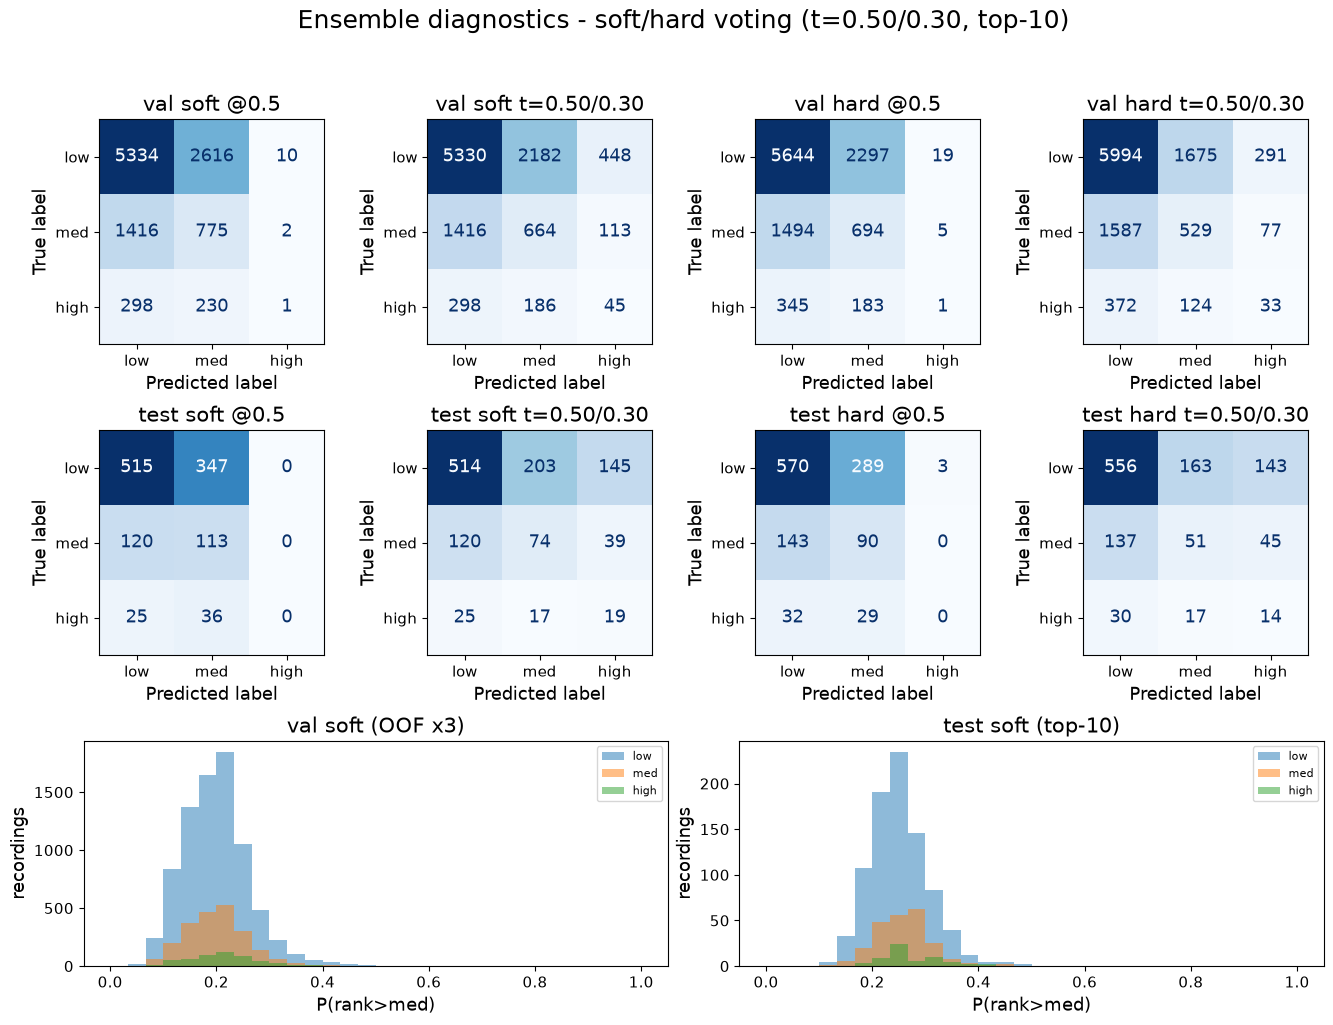

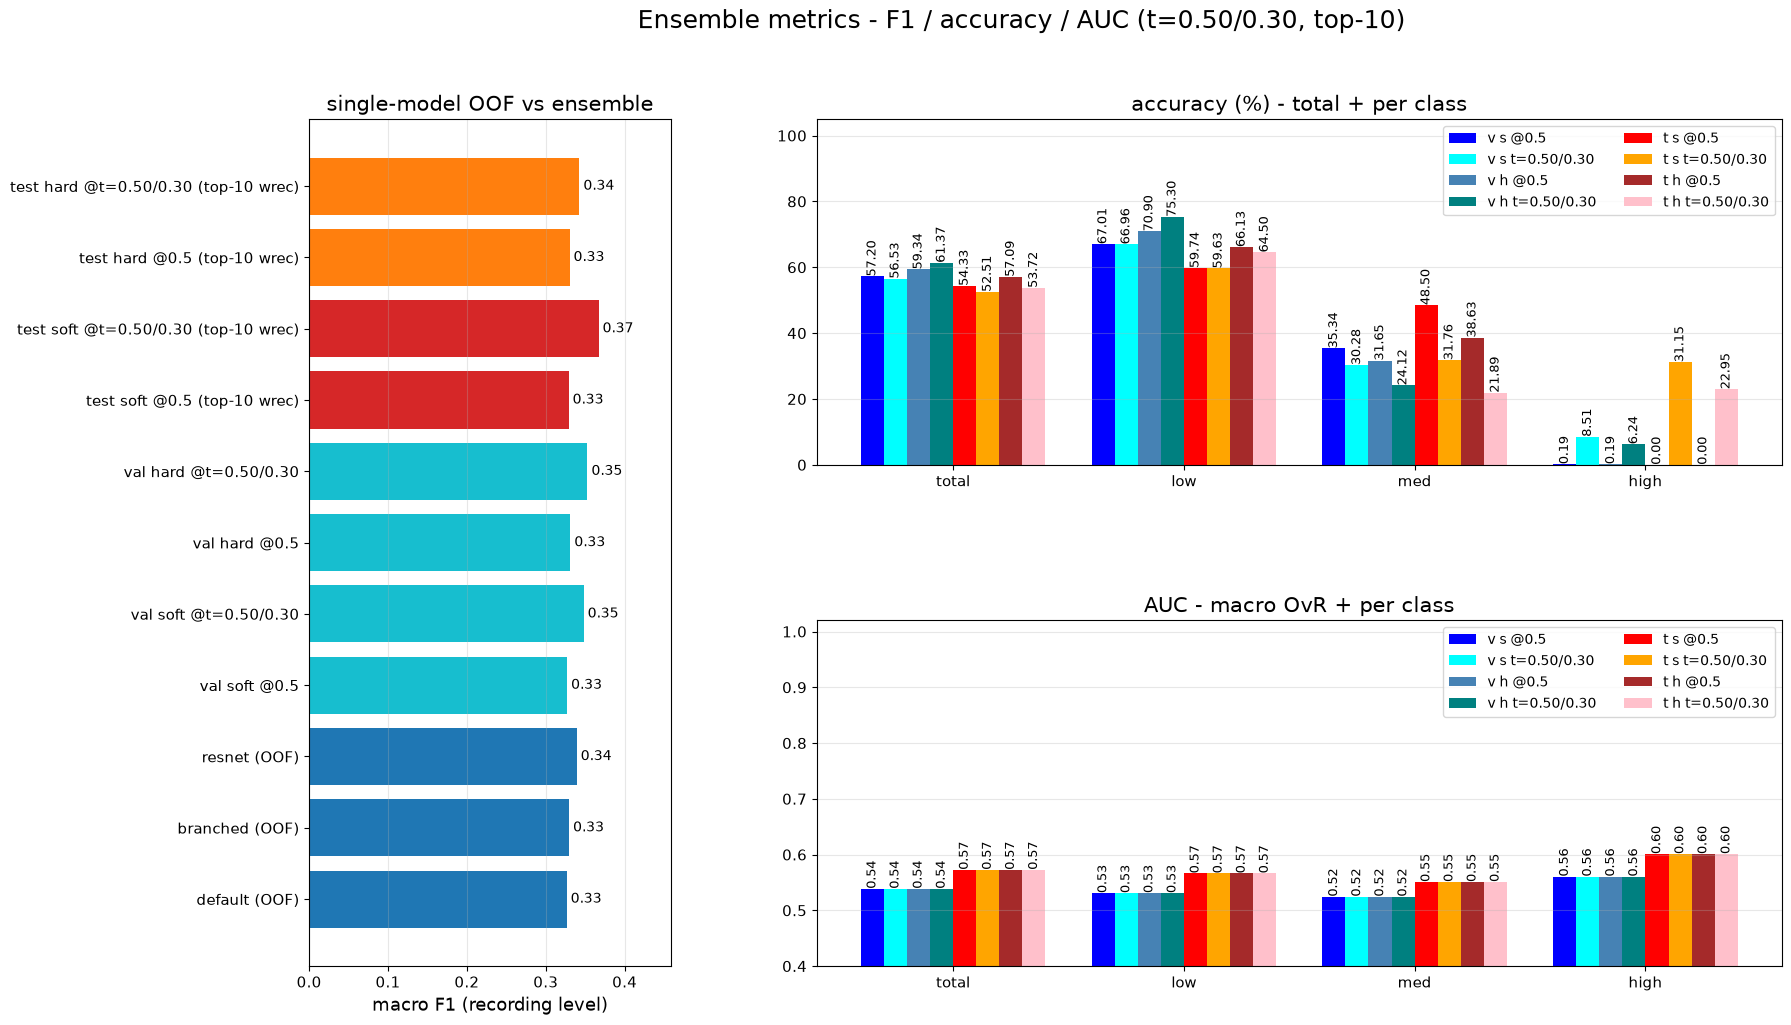

In [66]:
@contextlib.contextmanager
def ens_log():
    """Stdout/stderr redirect to the ensemble experiment log (truncate-on-rerun)."""
    os.makedirs("logs_3class", exist_ok=True)
    f = open("logs_3class/ensemble_experiment.txt", "w", encoding="utf-8")
    out, err = sys.stdout, sys.stderr
    sys.stdout = sys.stderr = f
    try:
        yield f
    finally:
        sys.stdout, sys.stderr = out, err
        f.close()

cv_models = CV_MODELS
N_ENS = len(cv_models)
ENS_RANK_NAMES: list[str] = ["low", "med", "high"]
TOP_N_MODELS: int = 10            # N checkpoints used in the test ensemble
HIGH_RECALL_WEIGHT: float = 1  # weighted-recall score: low/med get (1-w)/2 each, high gets w

def _class_scores(rec: dict) -> dict[str, np.ndarray]:
    p1, p2 = np.clip(rec["p1"], 0.0, 1.0), np.clip(rec["p2"], 0.0, 1.0)
    return {"low": 1.0 - p1, "med": p1 - p2, "high": p2}

def _ens_extra(rec: dict, pred: np.ndarray) -> dict:
    t = rec["true"]
    accs = {f"acc_{n}": round(100 * float(np.mean(pred[t == k] == k)), 2)
            for k, n in enumerate(["low", "med", "high"])}
    scores = _class_scores(rec)
    aucs = {f"auc_{n}": round(float(roc_auc_score((t == k).astype(int), s)), 4)
            if len(np.unique(t == k)) > 1 else None
            for k, (n, s) in enumerate(scores.items())}
    auc_vals = [v for v in aucs.values() if v is not None]
    return {"acc_total": round(100 * float(np.mean(pred == t)), 2), **accs,
            "auc_macro_ovr": round(float(np.mean(auc_vals)), 4) if auc_vals else None, **aucs}

def _ens_row(model_name: str, rec: dict, pred: np.ndarray | None = None) -> tuple[dict, dict]:
    p = rec["pred"] if pred is None else pred
    m = ordinal_oof_metrics(rec["true"], p, rec["p1"], rec["p2"])
    row = {"model": model_name, "n_recordings": len(rec["true"]),
           **{k: (round(v, 4) if v is not None else None) for k, v in m.items()},
           **_ens_extra(rec, p)}
    return row, m

def _predict_at(rec: dict, t1: float, t2: float) -> np.ndarray:
    return (rec["p1"] > t1).astype(int) + (rec["p2"] > t2).astype(int)

def _eval_at(rec: dict, t1: float, t2: float) -> dict:
    pred = _predict_at(rec, t1, t2)
    return {"t1": t1, "t2": t2,
            "macro_f1": round(f1_score(rec["true"], pred, average="macro", zero_division=0), 4),
            "acc": round(100 * float(np.mean(rec["true"] == pred)), 2)}

def _vote(votes: np.ndarray) -> np.ndarray:
    """Majority vote across models, shape (n_models, n_recs). Ties -> lower rank."""
    out = np.empty(votes.shape[1], dtype=int)
    for j in range(votes.shape[1]):
        counts = np.bincount(votes[:, j], minlength=3)
        out[j] = int(np.flatnonzero(counts == counts.max())[0])
    return out

def _strip_compile_prefix(state: dict) -> dict:
    return {k.removeprefix("_orig_mod."): v for k, v in state.items()}

def _feats(waveforms: torch.Tensor, raw: torch.Tensor, mel, use_sep: bool):
    waveforms = trim_tile(waveforms)
    feats = mel(waveforms, raw)
    if use_sep:
        spec, mfcc = feats
        if spec.ndim == 3:
            spec, mfcc = spec.unsqueeze(0), mfcc.unsqueeze(0)
        return spec, mfcc
    if feats.ndim == 3:
        feats = feats.unsqueeze(0)
    return feats

def _candidate_ckpts() -> list[dict]:
    """All saved checkpoints per fold: _best (val-F1) + _vloss0/1/2 + _latest.
    Scoring happens in _val_recall_score (recording-level val CM)."""
    out: list[dict] = []
    for mn in cv_models:
        for fi in range(N_FOLDS):
            key = f"cv__{mn}__f{fi}"
            paths = [_ckpt_best_path(key)] + [
                os.path.join(RUN_STATE_DIR, f"{key}_vloss{k}.pth.tar")
                for k in range(LOSS_TOP_N)
            ] 
            #+ [_ckpt_path(key)]
            seen: set[str] = set()
            for p in paths:
                if p in seen or not os.path.exists(p):
                    continue
                seen.add(p)
                _m = re.search(r"_vloss(\d+)\.pth\.tar$", os.path.basename(p))
                out.append({"mn": mn, "fi": fi, "path": p,
                            "vloss_rank": int(_m.group(1)) if _m else None})
    return out

def _val_recall_score(c: dict, weights: np.ndarray) -> dict:
    """One inference pass on this checkpoint's OWN val fold; score = weighted
    recall from the RECORDING-level confusion matrix. weights: [low, med, high]."""
    mn, fi, cp = c["mn"], c["fi"], c["path"]
    use_sep = (mn == "branched")
    st = torch.load(cp, weights_only=True, map_location=device)
    model = CoralOrdinal(_make_model(mn, num_classes=1)).to(device)
    model.load_state_dict(_strip_compile_prefix(st["model_state_dict"]))
    model.eval()
    _, va_pos = FOLDS[fi]
    idxs = [int(cv_pool[p]) for p in va_pos]
    loader = torch.utils.data.DataLoader(Subset(dataset, idxs), BATCH_SIZE,
                                         shuffle=False, num_workers=0, pin_memory=True)
    p1s, p2s = [], []
    with torch.inference_mode():
        for waveforms, labels in tqdm(loader, desc=f"[val-rank {os.path.basename(cp)}]", leave=False):
            waveforms = waveforms.to(device, non_blocking=True)
            raw = labels.long().to(device)
            feats = _feats(waveforms, raw, mel_eval_sep if use_sep else mel_eval, use_sep)
            probs = torch.sigmoid(model(feats).float())
            p1s.append(probs[:, 0].cpu().numpy())
            p2s.append(probs[:, 1].cpu().numpy())
    rec = aggregate_recordings({
        "path": np.asarray([dataset.get_path(i) for i in idxs], dtype=object),
        "true_rank": np.asarray([RANK[int(dataset.labels[i])] for i in idxs], dtype=int),
        "p1": np.concatenate(p1s), "p2": np.concatenate(p2s),
    })
    cm = confusion_matrix(rec["true"], rec["pred"], labels=[0, 1, 2])
    recalls = cm.diagonal() / cm.sum(axis=1).clip(min=1)
    del model
    torch.cuda.empty_cache() if device.type == "cuda" else None
    return {"score": round(float(np.dot(weights, recalls)), 4),
            "recall_low": round(float(recalls[0]), 4),
            "recall_med": round(float(recalls[1]), 4),
            "recall_high": round(float(recalls[2]), 4),
            "acc": round(100 * float(np.mean(rec["pred"] == rec["true"])), 2),
            "n_recordings": len(rec["true"])}
    

def _save_best_test_variant(all_rows, top_folds, out_csv, out_state,
                               metric: str = "macro_f1"):
        test_rows = [r for r in all_rows if str(r["model"]).startswith("test ")]
        assert test_rows, "no test rows to choose from"
        best = max(test_rows, key=lambda r: (r.get(metric) if r.get(metric) is not None else -np.inf,
                                             r.get("acc_total") if r.get("acc_total") is not None else -np.inf))
        name = str(best["model"])

        # recover the prediction array for the winning variant
        if "hard" in name:
            pred = test_hard_t if "t=" in name else test_hard_05
        else:
            pred = ens_test_pred_t if "t=" in name else ens_test_rec["pred"]
        best_rec = {**ens_test_rec, "pred": pred}

        ckpts = [{"model": c["mn"], "fold": c["fi"],
                  "ckpt": os.path.basename(c["path"]),
                  "vloss_rank": c.get("vloss_rank"),
                  "selection_score": c.get("score", c.get("loss"))}
                 for c in top_folds]

        row = {"selected_variant": name,
               "selection_metric": metric,
               "t1_used": t1 if "t=" in name else 0.5,
               "t2_used": t2 if "t=" in name else 0.5,
               "n_checkpoints_used": len(ckpts),
               "ckpts_used": "; ".join(
                   f"{c['model']} f{c['fold']} {c['ckpt']}" for c in ckpts),
               **best}

        pl.DataFrame([row]).write_csv(out_csv)
        torch.save({"best_row": row, "best_rec": best_rec,
                    "top_folds": ckpts},
                   out_state)
        print(f"=> saved BEST test variant: {name} "
              f"({metric}={row[metric]}, high recall={row.get('recall_high')}) "
              f"using {len(ckpts)} checkpoints -> {out_csv}")
        for c in ckpts:
            print(f"     {c['model']} f{c['fold']} {c['ckpt']} "
                  f"score={c['selection_score']}")


os.makedirs("figures_3class", exist_ok=True)

with ens_log():
    if "oof_all" not in globals() or not oof_all:
        _st = torch.load("run_state_3class/ordinal_oof_state.pt", weights_only=False)
        oof_all, cv_rows = _st["oof_all"], _st["cv_rows"]
        print("=> OOF state restored from run_state_3class/ordinal_oof_state.pt")

    _cached = "ens_val_rec" in globals() and "ens_test_rec" in globals() \
              and ens_val_rec and ens_test_rec
    top_folds: list[dict] = []
    val_family_recs: list[dict] = []
    test_model_recs: list[dict] = []
    if _cached:
        _est_path = "run_state_3class/ensemble_state.pt"
        if os.path.exists(_est_path):
            _est = torch.load(_est_path, weights_only=False)
            val_family_recs = _est.get("val_family_recs", [])
            test_model_recs = _est.get("test_model_recs", [])
            top_folds = _est.get("top_folds") or []
        if not val_family_recs or not test_model_recs:
            _cached = False
        else:
            print("=> ensemble recordings already in memory - skipping model loading")

    if not _cached:
        # --- 1) VAL soft OOF across families (reported from _best checkpoints) ---
        _lens = [len(oof_all[mn]["path"]) for mn in cv_models]
        assert len(set(_lens)) == 1, f"OOF arrays misaligned across models: {_lens}"
        ens_val_oof = {
            "path": oof_all["default"]["path"],
            "true_rank": oof_all["default"]["true_rank"],
            "p1": np.mean([oof_all[mn]["p1"] for mn in cv_models], axis=0),
            "p2": np.mean([oof_all[mn]["p2"] for mn in cv_models], axis=0),
        }
        ens_val_rec = aggregate_recordings(ens_val_oof)
        val_family_recs = [aggregate_recordings(oof_all[mn]) for mn in cv_models]
        assert len(set(len(r["true"]) for r in val_family_recs)) == 1

        # --- 2) rank candidates by weighted RECALL on their own val fold ---
        _w2 = float(HIGH_RECALL_WEIGHT)
        _weights = np.array([(1.0 - _w2) / 2.0, (1.0 - _w2) / 2.0, _w2])
        #_weights = np.array([1, 1, 1])
        print(f"\n=== scoring saved checkpoints on val: "
              f"low={_weights[0]:.2f} med={_weights[1]:.2f} high={_weights[2]:.2f} ===")
        candidates = _candidate_ckpts()
        assert candidates, "no saved checkpoints found for CV folds"
        scored = [_val_recall_score(c, _weights) | c for c in candidates]
        ranking = sorted(scored, key=lambda r: -r["score"])
        print("\n=== saved checkpoints ranked by val weighted recall (higher = better) ===")
        for i, c in enumerate(ranking):
            _tag = f"vloss{c['vloss_rank']}" if c["vloss_rank"] is not None else "best(F1)"
            print(f"  {i+1:2d}. {c['mn']} f{c['fi']} {os.path.basename(c['path'])} [{_tag}] "
                  f"score={c['score']:.4f} rec(L/M/H)={c['recall_low']:.2f}/"
                  f"{c['recall_med']:.2f}/{c['recall_high']:.2f} acc={c['acc']:.2f}%"
                  f"{'  <= USED' if i < TOP_N_MODELS else ''}")
        _b = ranking[0]
        print(f"\n=> BEST by weighted recall: {_b['mn']} f{_b['fi']} "
              f"{os.path.basename(_b['path'])} (score={_b['score']:.4f}, "
              f"high recall={_b['recall_high']:.4f})")
        top_folds = ranking[:TOP_N_MODELS]
        print(f"=> using top-{TOP_N_MODELS} weighted-recall checkpoints for TEST")

        pl.DataFrame([{"rank": i + 1, "model": c["mn"], "fold": c["fi"],
                       "ckpt": os.path.basename(c["path"]),
                       "vloss_rank": c["vloss_rank"], "score": round(c["score"], 4),
                       "recall_low": c["recall_low"], "recall_med": c["recall_med"],
                       "recall_high": c["recall_high"], "val_acc": c["acc"],
                       "used": i < TOP_N_MODELS} for i, c in enumerate(ranking)]
                     ).write_csv("tables_3class/ensemble_selected_ckpts.csv")

        test_loader = torch.utils.data.DataLoader(
            Subset(dataset, test_subset.indices), BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
        )
        test_paths = np.asarray([dataset.get_path(int(i)) for i in test_subset.indices], dtype=object)
        true_ranks = np.asarray([RANK[int(dataset.labels[i])] for i in test_subset.indices], dtype=int)
        p1_list: list[np.ndarray] = []
        p2_list: list[np.ndarray] = []
        for c in top_folds:
            mn, fi, cp = c["mn"], c["fi"], c["path"]
            use_sep = (mn == "branched")
            model = CoralOrdinal(_make_model(mn, num_classes=1)).to(device)
            model.load_state_dict(_strip_compile_prefix(
                torch.load(cp, weights_only=True, map_location=device)["model_state_dict"]))
            model.eval()
            p1s: list[torch.Tensor] = []
            p2s: list[torch.Tensor] = []
            with torch.inference_mode():
                for waveforms, labels in tqdm(test_loader, desc=f"[{os.path.basename(cp)}] test", leave=False):
                    waveforms = waveforms.to(device, non_blocking=True)
                    raw = labels.long().to(device)
                    feats = _feats(waveforms, raw, mel_eval_sep if use_sep else mel_eval, use_sep)
                    probs = torch.sigmoid(model(feats).float())
                    p1s.append(probs[:, 0].cpu())
                    p2s.append(probs[:, 1].cpu())
            p1_list.append(torch.cat(p1s).numpy())
            p2_list.append(torch.cat(p2s).numpy())
            del model
            torch.cuda.empty_cache() if device.type == "cuda" else None

        ens_test_oof = {"path": test_paths, "true_rank": true_ranks,
                        "p1": np.mean(p1_list, axis=0), "p2": np.mean(p2_list, axis=0)}
        ens_test_rec = aggregate_recordings(ens_test_oof)
        test_model_recs = [aggregate_recordings({"path": test_paths, "true_rank": true_ranks,
                                                 "p1": a, "p2": b}) for a, b in zip(p1_list, p2_list)]

    # --- 3) threshold sweep on VAL soft OOF (from _best OOF, unchanged) ---
    ens_val_row_s, _ = _ens_row("val soft @0.5", ens_val_rec)
    ens_test_row_s, _ = _ens_row(f"test soft @0.5 (top-{TOP_N_MODELS} wrec)", ens_test_rec)
    val_hard_05 = _vote(np.stack([_predict_at(r, 0.5, 0.5) for r in val_family_recs]))
    test_hard_05 = _vote(np.stack([_predict_at(r, 0.5, 0.5) for r in test_model_recs]))
    ens_val_row_h, _ = _ens_row("val hard @0.5", ens_val_rec, val_hard_05)
    ens_test_row_h, _ = _ens_row(f"test hard @0.5 (top-{TOP_N_MODELS} wrec)", ens_test_rec, test_hard_05)

    _t1 = np.arange(0.1, 0.71, 0.05)
    _t2 = np.arange(0.1, 0.71, 0.05)
    sweep = sorted((_eval_at(ens_val_rec, float(a), float(b)) for a in _t1 for b in _t2),
                   key=lambda r: -r["macro_f1"])
    print("\n=== threshold sweep (val soft only, top 8) ===")
    for s in sweep[:8]:
        print(s)
    best = sweep[0]
    t1, t2 = best["t1"], best["t2"]
    print(f"\nval-best thresholds: t1={t1:.2f} t2={t2:.2f} macro_f1={best['macro_f1']}")

    ens_val_pred_t = _predict_at(ens_val_rec, t1, t2)
    ens_test_pred_t = _predict_at(ens_test_rec, t1, t2)
    val_hard_t = _vote(np.stack([_predict_at(r, t1, t2) for r in val_family_recs]))
    test_hard_t = _vote(np.stack([_predict_at(r, t1, t2) for r in test_model_recs]))
    ens_val_row_st, _ = _ens_row(f"val soft @t={t1:.2f}/{t2:.2f}", ens_val_rec, ens_val_pred_t)
    ens_test_row_st, _ = _ens_row(f"test soft @t={t1:.2f}/{t2:.2f} (top-{TOP_N_MODELS} wrec)", ens_test_rec, ens_test_pred_t)
    ens_val_row_ht, _ = _ens_row(f"val hard @t={t1:.2f}/{t2:.2f}", ens_val_rec, val_hard_t)
    ens_test_row_ht, _ = _ens_row(f"test hard @t={t1:.2f}/{t2:.2f} (top-{TOP_N_MODELS} wrec)", ens_test_rec, test_hard_t)

    all_rows = [ens_val_row_s, ens_val_row_st, ens_val_row_h, ens_val_row_ht,
                ens_test_row_s, ens_test_row_st, ens_test_row_h, ens_test_row_ht]
    print("\n=== all ensemble rows (val/test x soft/hard x 0.5/tuned) ===")
    for r in all_rows:
        print(r)
        
    _save_best_test_variant(all_rows, top_folds,
                           "tables_3class/final_best_test_variant.csv",
                           "run_state_3class/final_best_test_variant.pt")

    pl.DataFrame(all_rows).write_csv("tables_3class/ensemble_eval.csv")
    _tmp = "run_state_3class/ensemble_state.pt.tmp"
    torch.save({"val_rec": ens_val_rec, "test_rec": ens_test_rec, "rows": all_rows,
                "val_family_recs": val_family_recs, "test_model_recs": test_model_recs,
                "best_thresholds": {"t1": t1, "t2": t2},
                "top_folds": top_folds or None}, _tmp)
    os.replace(_tmp, "run_state_3class/ensemble_state.pt")
    print("=> ensemble_eval.csv, ensemble_selected_ckpts.csv, ensemble_state.pt written")

    # --- 4) figures: two combined images ---
_tt = f"t={t1:.2f}/{t2:.2f}"
os.makedirs("figures_3class", exist_ok=True)

import matplotlib.pyplot as plt
_RC_KEYS = ("font.size", "axes.titlesize", "axes.labelsize",
            "xtick.labelsize", "ytick.labelsize", "legend.fontsize", "figure.titlesize")
_rc_old = {k: plt.rcParams[k] for k in _RC_KEYS}
plt.rcParams.update({
    "font.size": 13, "axes.titlesize": 15, "axes.labelsize": 13,
    "xtick.labelsize": 11, "ytick.labelsize": 11,
    "legend.fontsize": 11, "figure.titlesize": 18,
})

# ============ FIGURE 1: CMs + P(p2) histograms ============
_cases = [("val soft @0.5", ens_val_rec, ens_val_rec["pred"]),
          (f"val soft {_tt}", ens_val_rec, ens_val_pred_t),
          ("val hard @0.5", ens_val_rec, val_hard_05),
          (f"val hard {_tt}", ens_val_rec, val_hard_t),
          ("test soft @0.5", ens_test_rec, ens_test_rec["pred"]),
          (f"test soft {_tt}", ens_test_rec, ens_test_pred_t),
          ("test hard @0.5", ens_test_rec, test_hard_05),
          (f"test hard {_tt}", ens_test_rec, test_hard_t)]

fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(3, 4, hspace=0.38, wspace=0.28)
cm_axes = [fig.add_subplot(gs[i, j]) for i in range(2) for j in range(4)]
for ax, (title, rec, pred) in zip(cm_axes, _cases):
    cm = confusion_matrix(rec["true"], pred, labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=ENS_RANK_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)

_ax_vh = fig.add_subplot(gs[2, 0:2])
_ax_th = fig.add_subplot(gs[2, 2:4])
for ax, title, rec in [(_ax_vh, f"val soft (OOF x{N_ENS})", ens_val_rec),
                       (_ax_th, f"test soft (top-{TOP_N_MODELS})", ens_test_rec)]:
    for r in range(3):
        ax.hist(rec["p2"][rec["true"] == r], bins=30, alpha=0.5, range=(0, 1),
                label=ENS_RANK_NAMES[r])
    ax.set_title(title); ax.set_xlabel("P(rank>med)"); ax.set_ylabel("recordings")
    ax.legend(fontsize=8)

fig.suptitle(f"Ensemble diagnostics - soft/hard voting ({_tt}, top-{TOP_N_MODELS})", fontsize=18)
fig.savefig("figures_3class/ensemble_combined_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show(fig); plt.close(fig)

# ============ FIGURE 2: F1 compare + accuracy/AUC grouped bars ============
_comp_rows: list[tuple[str, float]] = []
if "eval_rows" in globals() and eval_rows:
    _comp_rows += [(f"{r['model']} (OOF)", r["macro_f1"]) for r in eval_rows]
_comp_rows += [(r["model"], r["macro_f1"]) for r in all_rows]

fig2 = plt.figure(figsize=(19, 11))
gs2 = fig2.add_gridspec(1, 2, width_ratios=[0.9, 2.4], wspace=0.22)
_ax_f1 = fig2.add_subplot(gs2[0, 0])
_inner = gs2[0, 1].subgridspec(2, 1, hspace=0.45)
_ax_acc = fig2.add_subplot(_inner[0])
_ax_auc = fig2.add_subplot(_inner[1])

_vals = [c[1] for c in _comp_rows]
_cols = ["tab:blue"] * (len(_vals) - 8) + ["tab:cyan"] * 4 + ["tab:red", "tab:red", "tab:orange", "tab:orange"]
_ax_f1.barh([c[0] for c in _comp_rows], _vals, color=_cols)
_ax_f1.set_xlabel("macro F1 (recording level)")
_ax_f1.set_xlim(0, max(_vals) * 1.25 or 1.0)
_ax_f1.set_title("single-model OOF vs ensemble")
_ax_f1.grid(axis="x", alpha=0.3)
for i, v in enumerate(_vals):
    _ax_f1.text(v, i, f" {v:.2f}", va="center", fontsize=10)

_acc_keys = ["acc_total", "acc_low", "acc_med", "acc_high"]
_auc_keys = ["auc_macro_ovr", "auc_low", "auc_med", "auc_high"]
_metric_rows = [("v s @0.5", ens_val_row_s, "blue"),
                (f"v s {_tt}", ens_val_row_st, "cyan"),
                ("v h @0.5", ens_val_row_h, "steelblue"),
                (f"v h {_tt}", ens_val_row_ht, "teal"),
                ("t s @0.5", ens_test_row_s, "red"),
                (f"t s {_tt}", ens_test_row_st, "orange"),
                ("t h @0.5", ens_test_row_h, "brown"),
                (f"t h {_tt}", ens_test_row_ht, "pink")]
_x = np.arange(4)
_w = 0.1
for gi, (lbl, row, col) in enumerate(_metric_rows):
    _ax_acc.bar(_x + (gi - 3.5) * _w,
                [row[k] for k in _acc_keys], _w, label=lbl, color=col)
    _ax_auc.bar(_x + (gi - 3.5) * _w,
                [row[k] if row[k] is not None else np.nan for k in _auc_keys],
                _w, label=lbl, color=col)
for ax, keys, title, ylim in [(_ax_acc, _acc_keys, "accuracy (%) - total + per class", (0, 105)),
                              (_ax_auc, _auc_keys, "AUC - macro OvR + per class", (0.4, 1.02))]:
    ax.set_xticks(_x)
    ax.set_xticklabels(["total", "low", "med", "high"])
    ax.set_title(title); ax.set_ylim(*ylim)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=10, ncol=2)
    for gi, (lbl, row, _) in enumerate(_metric_rows):
        for xi, k in enumerate(keys):
            v = row[k]
            if v is not None:
                ax.text(xi + (gi - 3.5) * _w, v, f"{v:.2f}",
                        ha="center", va="bottom", fontsize=9, rotation=90)

fig2.suptitle(f"Ensemble metrics - F1 / accuracy / AUC ({_tt}, top-{TOP_N_MODELS})", fontsize=18)
fig2.savefig("figures_3class/ensemble_combined_metrics.png", dpi=150, bbox_inches="tight")
plt.show(fig2); plt.close(fig2)

print("=> ensemble_combined_diagnostics.png + ensemble_combined_metrics.png written")

In [77]:
print("hello")

[default] test:   0%|          | 0/22 [00:00<?, ?it/s]

[branched] test:   0%|          | 0/22 [00:00<?, ?it/s]

[resnet] test:   0%|          | 0/22 [00:00<?, ?it/s]

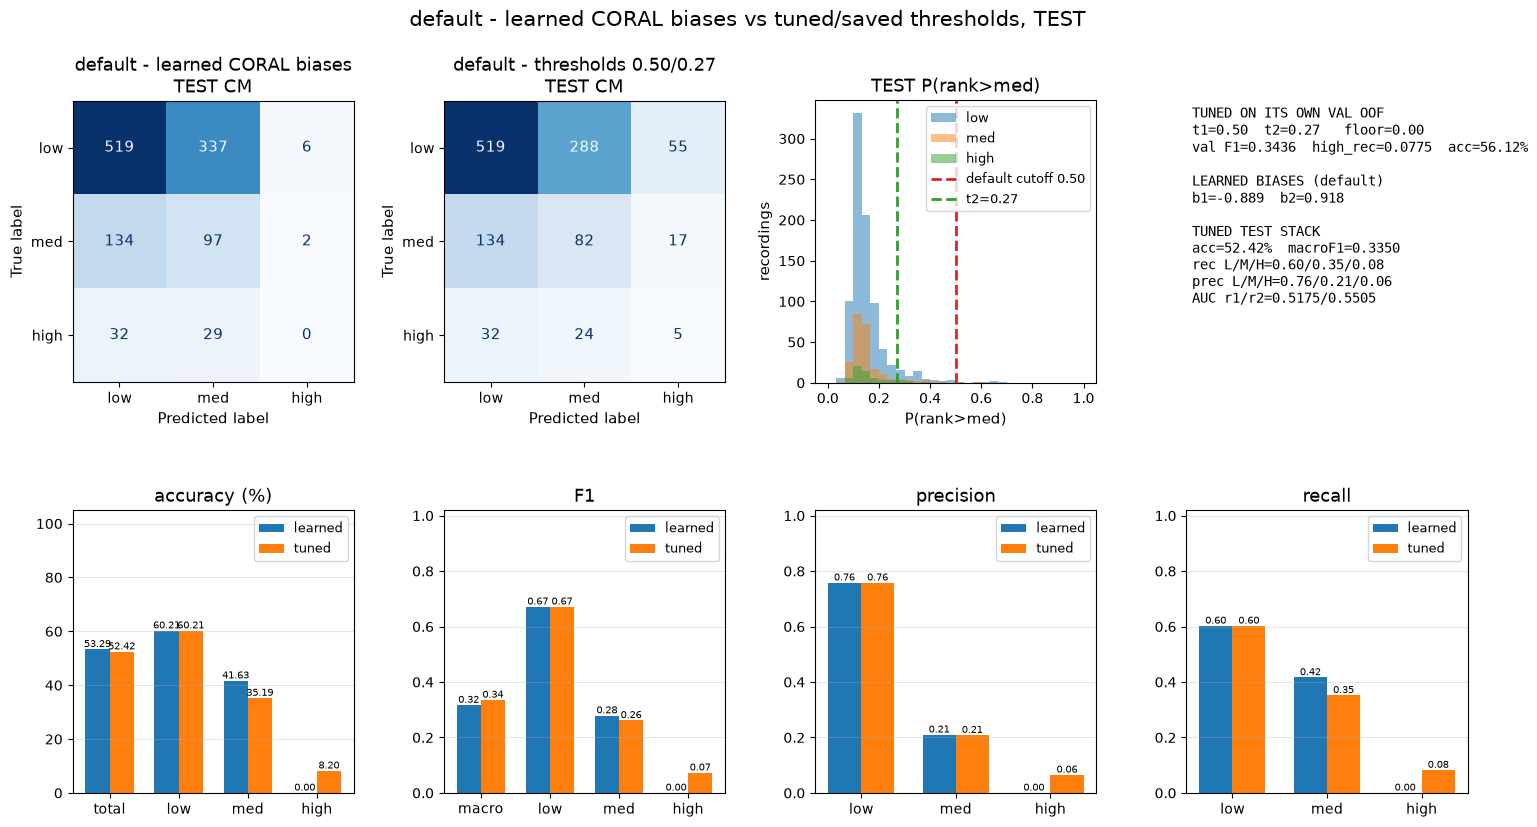

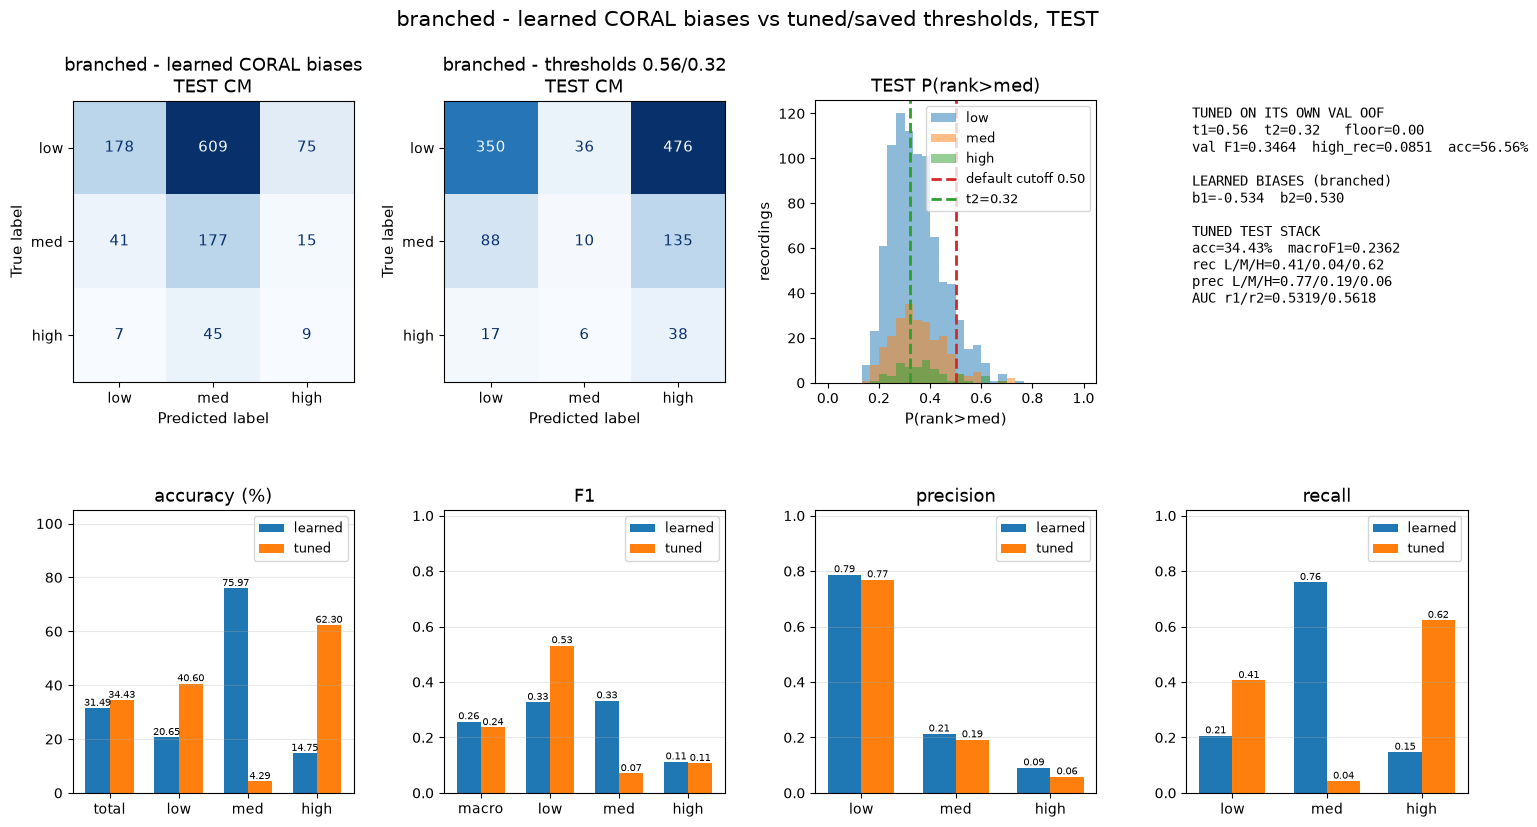

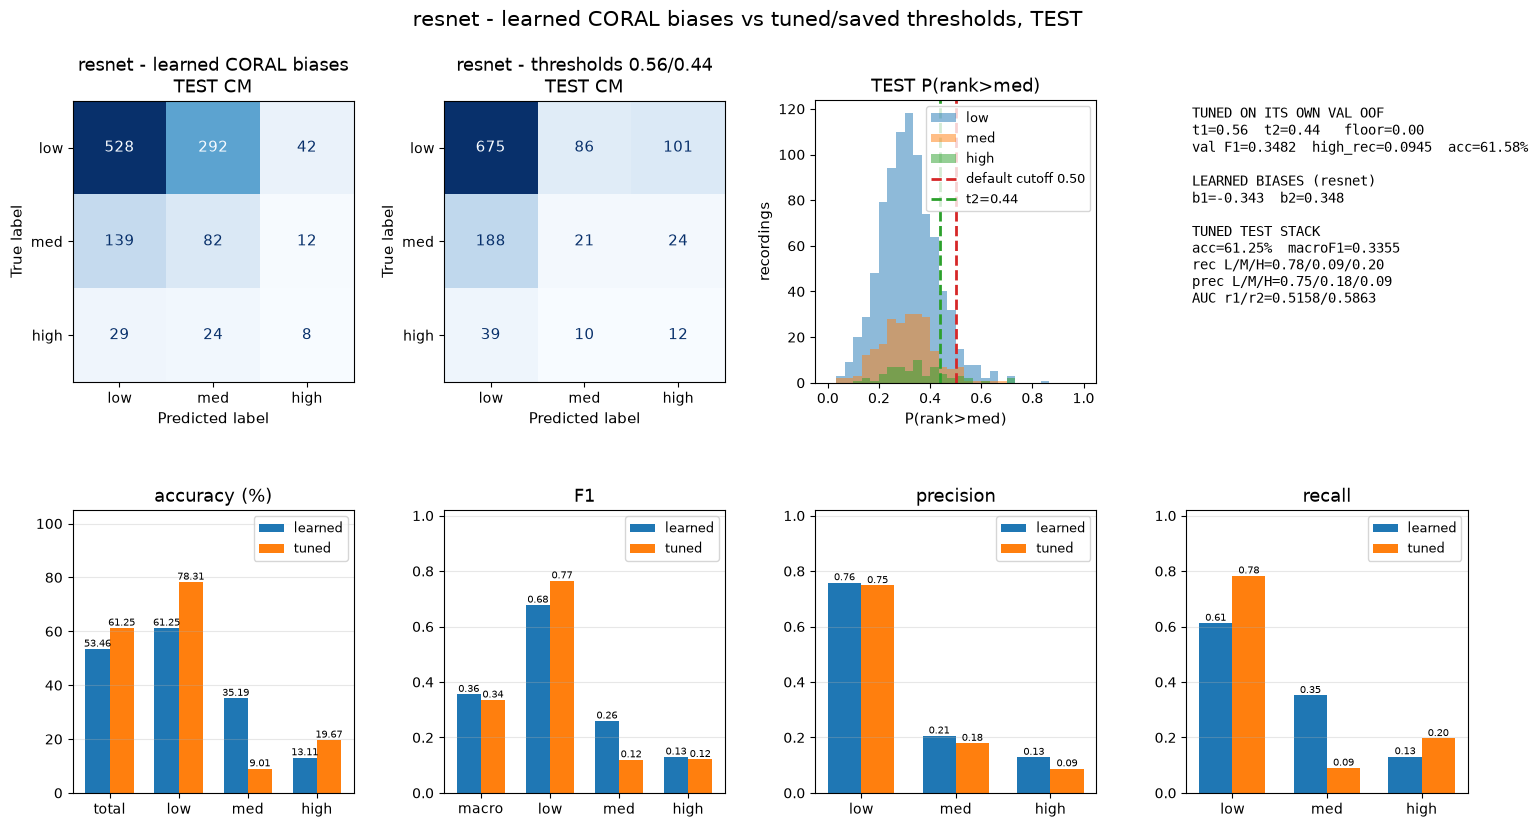

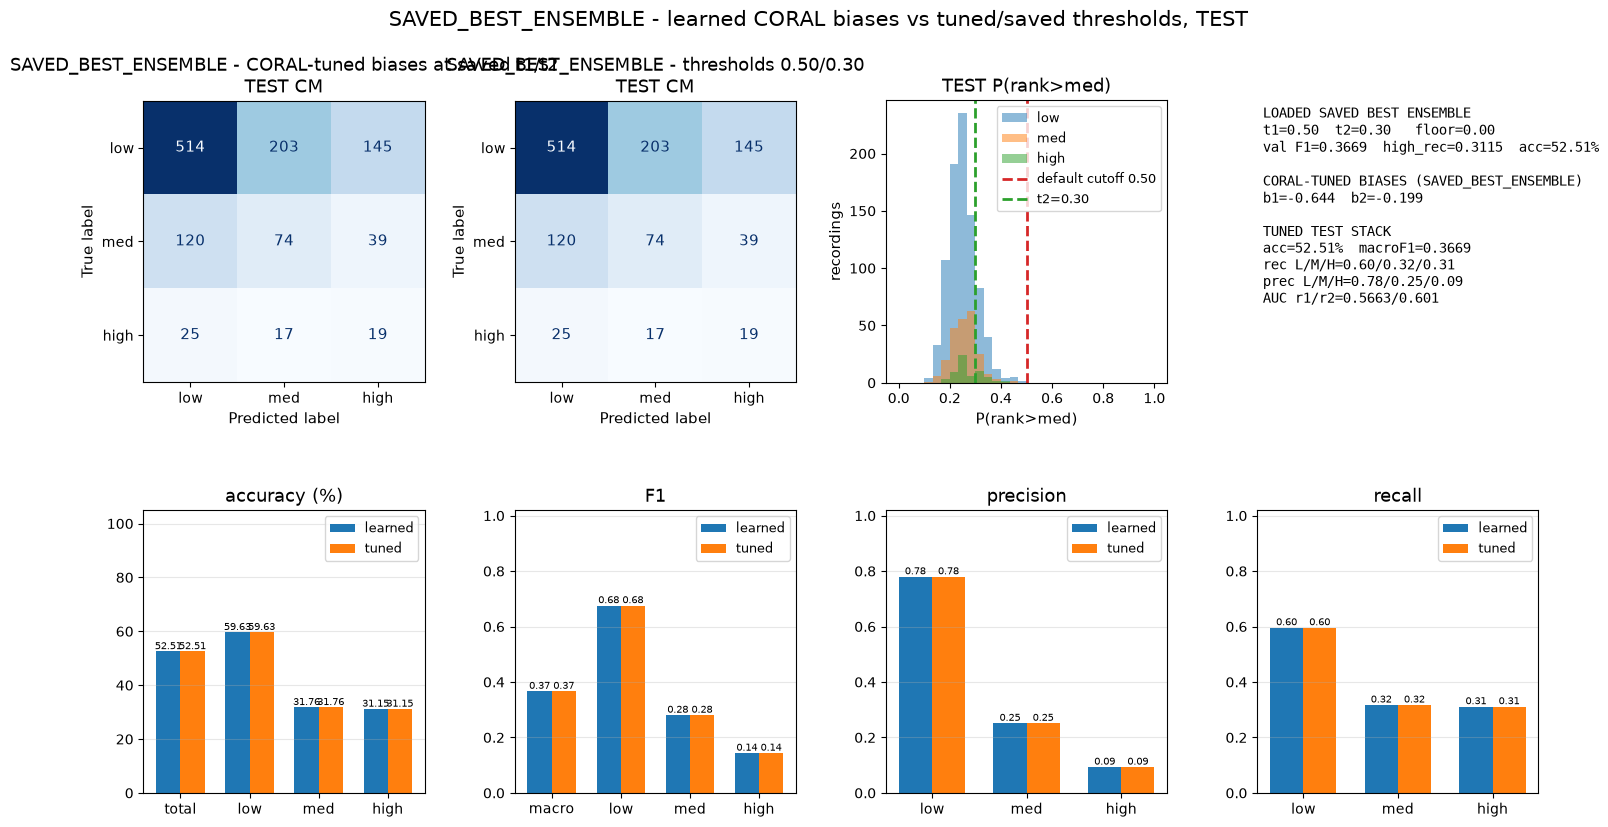

In [79]:
# ---- per-model CORAL thresholds (own VAL) + load saved best ensemble ----
import os
import numpy as np
import polars as pl
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, ConfusionMatrixDisplay
from tqdm.auto import tqdm

OUT_CSV = "tables_3class/coral_threshold_per_model_test_eval.csv"
BEST_CSV = "tables_3class/final_best_coral_tune.csv"
BEST_STATE = "run_state_3class/final_best_coral_tune.pt"
FINAL_ENS_STATE = "run_state_3class/final_best_test_variant.pt"
RANK_NAMES: list[str] = ["low", "med", "high"]
HIGH_RECALL_FLOOR: float = 0.0

def _strip_prefix(sd: dict) -> dict:
    return {k.removeprefix("_orig_mod."): v for k, v in sd.items()}

def _logit(x):
    x = np.clip(np.asarray(x, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(x / (1 - x))

def _predict(rec: dict, t1: float, t2: float) -> np.ndarray:
    """Soft-voted ensemble at probability cutoffs t1/t2."""
    return (rec["p1"] > t1).astype(int) + (rec["p2"] > t2).astype(int)

def _coral_tune_biases(biases: np.ndarray, t1: float, t2: float) -> np.ndarray:
    """CORAL tuning: turn soft-voting cutoffs into tuned cumulative biases."""
    return np.array([float(biases[0]) + float(_logit(t1)),
                     float(biases[1]) + float(_logit(t2))])

def _predict_coral(rec: dict, tuned_b: np.ndarray, base_b: np.ndarray) -> np.ndarray:
    """CORAL head at its fixed 0.5 cutoff, using the tuned biases."""
    d1, d2 = float(tuned_b[0] - base_b[0]), float(tuned_b[1] - base_b[1])
    p1 = 1.0 / (1.0 + np.exp(-(_logit(rec["p1"]) - d1)))
    p2 = 1.0 / (1.0 + np.exp(-(_logit(rec["p2"]) - d2)))
    return (p1 > 0.5).astype(int) + (p2 > 0.5).astype(int)

def _predict_learned(rec: dict, biases: np.ndarray) -> np.ndarray:
    b1, b2 = float(biases[0]), float(biases[1])
    s1 = _logit(rec["p1"]) + b1
    s2 = _logit(rec["p2"]) + b2
    return (s1 > b1).astype(int) + (s2 > b2).astype(int)

def _biases_of(cp: str) -> np.ndarray:
    sd = torch.load(cp, weights_only=True, map_location="cpu")["model_state_dict"]
    bs = [v for k, v in _strip_prefix(sd).items() if k.endswith("biases")]
    return np.asarray(bs[0].numpy(), dtype=float) if bs else np.array([np.nan, np.nan])

def _cand_path(c: dict) -> str:
    return c.get("path") or os.path.join(RUN_STATE_DIR, c["ckpt"])

def _cand_model(c: dict) -> str:
    return c.get("mn", c.get("model"))

def _cand_fold(c: dict) -> int:
    return int(c.get("fi", c.get("fold", -1)))

def _feats_eval(waveforms, raw, mel, use_sep: bool):
    waveforms = trim_tile(waveforms)
    feats = mel(waveforms, raw)
    if use_sep:
        spec, mfcc = feats
        if spec.ndim == 3:
            spec, mfcc = spec.unsqueeze(0), mfcc.unsqueeze(0)
        return spec, mfcc
    if feats.ndim == 3:
        feats = feats.unsqueeze(0)
    return feats

def _tune(val_rec: dict) -> tuple[list[tuple], tuple]:
    """Search symmetric bias shifts d = logit(t); b* = b + d."""
    cands: list[tuple] = []
    for d1 in np.arange(-2.0, 2.01, 0.25):
        for d2 in np.arange(-2.0, 2.01, 0.25):
            a = 1.0 / (1.0 + np.exp(-d1))
            b = 1.0 / (1.0 + np.exp(-d2))
            p = _predict(val_rec, a, b)
            rh = float(np.mean(p[val_rec["true"] == 2] == 2))
            f1 = float(f1_score(val_rec["true"], p, average="macro", zero_division=0))
            acc = 100 * float(np.mean(p == val_rec["true"]))
            cands.append((round(f1, 4), round(a, 2), round(b, 2),
                          round(rh, 4), round(acc, 2),
                          round(float(d1), 2), round(float(d2), 2)))
    q = [c for c in cands if c[3] >= HIGH_RECALL_FLOOR]
    if not q:
        q = cands
    ranked = sorted(q, key=lambda c: (-c[0], -c[3]))
    return ranked, ranked[0]

def _full(rec: dict, pred: np.ndarray) -> tuple[dict, np.ndarray]:
    t = rec["true"]
    cm = confusion_matrix(t, pred, labels=[0, 1, 2])
    recalls = cm.diagonal() / cm.sum(axis=1).clip(min=1)
    precisions = cm.diagonal() / cm.sum(axis=0).clip(min=1)
    f1s = f1_score(t, pred, average=None, labels=[0, 1, 2], zero_division=0)
    m = ordinal_oof_metrics(t, pred, rec["p1"], rec["p2"])
    p1, p2 = np.clip(rec["p1"], 0, 1), np.clip(rec["p2"], 0, 1)
    scores = {"low": 1 - p1, "med": p1 - p2, "high": p2}
    aucs = {f"auc_{n}": (round(float(roc_auc_score((t == k).astype(int), s)), 4)
                        if len(np.unique(t == k)) > 1 else None)
            for k, (n, s) in enumerate(scores.items())}
    out = {"acc_total": round(100 * float(np.mean(pred == t)), 2),
           "macro_f1": round(float(f1s.mean()), 4)}
    for k, n in enumerate(RANK_NAMES):
        out[f"acc_{n}"] = round(100 * float(np.mean(pred[t == k] == k)), 2)
        out[f"recall_{n}"] = round(float(recalls[k]), 4)
        out[f"precision_{n}"] = round(float(precisions[k]), 4)
        out[f"f1_{n}"] = round(float(f1s[k]), 4)
    out.update({k: (round(v, 4) if v is not None else None) for k, v in m.items()})
    out.update(aucs)
    return out, cm

# ============================================================
# 1) VAL recs + saved best ensemble
# ============================================================
_st = torch.load("run_state_3class/ordinal_oof_state.pt", weights_only=False)
_ens_path = "run_state_3class/ensemble_state.pt"
_ens = torch.load(_ens_path, weights_only=False) if os.path.exists(_ens_path) else {}
top_folds = _ens.get("top_folds") or []

val_recs: dict[str, dict] = {mn: aggregate_recordings(_st["oof_all"][mn]) for mn in CV_MODELS}
if _ens.get("val_rec"):
    val_recs["ENSEMBLE"] = _ens["val_rec"]

loaded_best_ens = None
if os.path.exists(FINAL_ENS_STATE):
    loaded_best_ens = torch.load(FINAL_ENS_STATE, weights_only=False)

# ============================================================
# 2) TEST recs, learned biases, checkpoints used
# ============================================================
test_loader = torch.utils.data.DataLoader(
    Subset(dataset, test_subset.indices), BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_paths = np.asarray([dataset.get_path(int(i)) for i in test_subset.indices], dtype=object)
true_ranks = np.asarray([RANK[int(dataset.labels[i])] for i in test_subset.indices], dtype=int)

sel = pl.read_csv("tables_3class/ensemble_selected_ckpts.csv").with_columns(
    pl.col("rank").cast(pl.Int64))
recs: dict[str, dict] = {}
ckpt_biases: dict[str, np.ndarray] = {}
coral_biases_used: dict[str, np.ndarray] = {}
used_ckpts: dict[str, dict] = {}

for mn in CV_MODELS:
    sub = sel.filter(pl.col("model") == mn).sort("rank")
    if not len(sub):
        print(f"!! no selected checkpoint for {mn}")
        continue
    r = sub.row(0, named=True)
    cp = os.path.join(RUN_STATE_DIR, r["ckpt"])
    ckpt_biases[mn] = _biases_of(cp)
    used_ckpts[mn] = {"fold": int(r["fold"]), "path": cp, "ckpts": []}
    use_sep = (mn == "branched")
    model = CoralOrdinal(_make_model(mn, num_classes=1)).to(device)
    model.load_state_dict(_strip_prefix(
        torch.load(cp, weights_only=True, map_location=device)["model_state_dict"]))
    model.eval()
    p1s, p2s = [], []
    with torch.inference_mode():
        for waveforms, labels in tqdm(test_loader, desc=f"[{mn}] test", leave=False):
            waveforms = waveforms.to(device, non_blocking=True)
            raw = labels.long().to(device)
            feats = _feats_eval(waveforms, raw, mel_eval_sep if use_sep else mel_eval, use_sep)
            probs = torch.sigmoid(model(feats).float())
            p1s.append(probs[:, 0].cpu().numpy())
            p2s.append(probs[:, 1].cpu().numpy())
    recs[mn] = aggregate_recordings({"path": test_paths, "true_rank": true_ranks,
                                     "p1": np.concatenate(p1s), "p2": np.concatenate(p2s)})
    del model
    torch.cuda.empty_cache() if device.type == "cuda" else None

if _ens.get("test_rec"):
    recs["ENSEMBLE"] = _ens["test_rec"]
    used_ckpts["ENSEMBLE"] = {"fold": None, "path": None, "ckpts": top_folds}
    if top_folds:
        ckpt_biases["ENSEMBLE"] = np.nanmean(
            [_biases_of(_cand_path(c)) for c in top_folds], axis=0)

if loaded_best_ens and loaded_best_ens.get("best_rec"):
    recs["SAVED_BEST_ENSEMBLE"] = loaded_best_ens["best_rec"]
    saved_tops = loaded_best_ens.get("top_folds") or top_folds
    used_ckpts["SAVED_BEST_ENSEMBLE"] = {"fold": None, "path": None, "ckpts": saved_tops}
    if saved_tops:
        ckpt_biases["SAVED_BEST_ENSEMBLE"] = np.nanmean(
            [_biases_of(_cand_path(c)) for c in saved_tops], axis=0)
    print("=> loaded SAVED_BEST_ENSEMBLE from", FINAL_ENS_STATE)

# ============================================================
# 3) tune on own VAL, test on own TEST; saved ensemble uses saved t
# ============================================================
rows: list[dict] = []
results: dict[str, dict] = {}
print("\n=== per-model CORAL thresholds (own VAL) + saved best ensemble ===")
for mn, rec in recs.items():
    if mn == "ENSEMBLE":
        continue
    is_saved = (mn == "SAVED_BEST_ENSEMBLE")
    if is_saved:
        _br = loaded_best_ens.get("best_row", {})
        a = float(_br.get("t1_used", 0.5))
        b = float(_br.get("t2_used", 0.5))
        ranked = []
        f1_v = float(_br.get("macro_f1", np.nan))
        rh_v = float(_br.get("recall_high", np.nan))
        acc_v = float(_br.get("acc_total", np.nan))
        print(f"[{mn}] LOADED soft-voting thresholds t1={a:.2f} t2={b:.2f} from saved best row")
    else:
        if mn not in val_recs:
            print(f"!! no val rec for {mn}; skipping")
            continue
        ranked, best = _tune(val_recs[mn])
        f1_v, a, b, rh_v, acc_v, d1, d2 = best
        print(f"[{mn}] t1={a:.2f} t2={b:.2f} d1={d1:+.2f} d2={d2:+.2f} | "
              f"val F1={f1_v:.4f} high_rec={rh_v:.4f} acc={acc_v:.2f}%")

    tuned_pred = _predict(rec, a, b)          # soft-voted ensemble at t1/t2
    tuned_m, tuned_cm = _full(rec, tuned_pred)
    if is_saved:
        # CORAL TUNING: convert the saved soft-voting cutoffs into tuned biases
        # and apply them through the CORAL head at its fixed 0.5 cutoff.
        base_b = ckpt_biases[mn]
        tuned_b = _coral_tune_biases(base_b, a, b)
        base_pred = _predict_coral(rec, tuned_b, base_b)
        coral_biases_used[mn] = tuned_b
        assert np.array_equal(base_pred, tuned_pred), \
            f"{mn}: tuned CORAL biases must reproduce the soft-voted thresholds"
    else:
        base_pred = _predict_learned(rec, ckpt_biases[mn])
        coral_biases_used[mn] = ckpt_biases[mn]
    base_m, base_cm = _full(rec, base_pred)

    tuned_name = "saved_tuned" if is_saved else "tuned"
    results[mn] = {"base": (base_m, base_cm), "tuned": (tuned_m, tuned_cm),
                   "rec": rec, "t1": a, "t2": b,
                   "val": (f1_v, rh_v, acc_v), "ranked": ranked,
                   "preds": {"learned_coral": base_pred, tuned_name: tuned_pred}}
    for variant, metrics, t1_r, t2_r in [
        ("learned_coral", base_m, None, None),
        (tuned_name, tuned_m, a, b),
    ]:
        rows.append({"model": mn, "variant": variant,
                     "t1": t1_r, "t2": t2_r,
                     "learned_b1": round(float(ckpt_biases[mn][0]), 4),
                     "learned_b2": round(float(ckpt_biases[mn][1]), 4),
                     "tune_source": "saved ensemble" if is_saved else f"{mn} VAL OOF",
                     "val_F1": f1_v, "val_high_recall": rh_v, "val_acc": acc_v,
                     "n_recordings": len(rec["true"]), **metrics})

pl.DataFrame(rows).write_csv(OUT_CSV)
print("\n=== TEST: learned biases vs tuned/saved thresholds ===")
print(pl.DataFrame(rows).select(["model", "variant", "t1", "t2", "acc_total", "macro_f1",
                                 "recall_low", "recall_med", "recall_high"]))
print(f"=> wrote {OUT_CSV}")

# ============================================================
# 4) save best overall result + the checkpoints it used
# ============================================================
def _save_best_tune_result(rows, results, used_ckpts,
                           out_csv, out_state, metric: str = "macro_f1"):
    best = max(rows, key=lambda r: (r.get(metric) if r.get(metric) is not None else -np.inf,
                                    r.get("acc_total") if r.get("acc_total") is not None else -np.inf))
    mn, variant = best["model"], best["variant"]
    rec = results[mn]["rec"]
    pred = results[mn]["preds"][variant]

    u = used_ckpts[mn]
    tops = u.get("ckpts") or []
    if tops:
        ckpts = [{"model": _cand_model(c), "fold": _cand_fold(c),
                  "ckpt": os.path.basename(_cand_path(c)),
                  "selection_score": c.get("score", c.get("loss"))}
                 for c in tops]
    else:
        ckpts = [{"model": mn, "fold": u["fold"],
                  "ckpt": os.path.basename(u["path"]),
                  "selection_score": "rank-1 val-selected"}]

    row = {"best_model": mn, "best_variant": variant,
           "selection_metric": metric,
           "t1_used": best.get("t1"), "t2_used": best.get("t2"),
           "learned_b1": best.get("learned_b1"), "learned_b2": best.get("learned_b2"),
           "n_checkpoints_used": len(ckpts),
           "ckpts_used": "; ".join(f"{c['model']} f{c['fold']} {c['ckpt']}" for c in ckpts),
           **best}
    pl.DataFrame([row]).write_csv(out_csv)
    torch.save({"best_row": row, "rec": rec, "pred": pred, "top_folds": ckpts}, out_state)
    print(f"=> saved BEST: {mn} / {variant} ({metric}={row[metric]}, "
          f"high recall={row.get('recall_high')}) using {len(ckpts)} checkpoint(s)")

_save_best_tune_result(rows, results, used_ckpts, BEST_CSV, BEST_STATE)

# ============================================================
# 5) one combined figure per model/variant
# ============================================================
os.makedirs("figures_3class", exist_ok=True)
_RC_KEYS = ("font.size", "axes.titlesize", "axes.labelsize",
            "xtick.labelsize", "ytick.labelsize", "legend.fontsize", "figure.titlesize")
_rc_old = {k: plt.rcParams[k] for k in _RC_KEYS}
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11,
                     "xtick.labelsize": 10, "ytick.labelsize": 10,
                     "legend.fontsize": 9, "figure.titlesize": 15})

for mn, res in results.items():
    rec = res["rec"]
    base_m, base_cm = res["base"]
    tuned_m, tuned_cm = res["tuned"]
    t1, t2 = res["t1"], res["t2"]
    f1_v, rh_v, acc_v = res["val"]
    base_title = ("CORAL-tuned biases at saved t1/t2"
                  if mn == "SAVED_BEST_ENSEMBLE" else "learned CORAL biases")

    fig = plt.figure(figsize=(18, 9))
    gs = fig.add_gridspec(2, 4, hspace=0.45, wspace=0.32)

    for col, (cm, title) in enumerate([(base_cm, base_title),
                                       (tuned_cm, f"thresholds {t1:.2f}/{t2:.2f}")]):
        ax = fig.add_subplot(gs[0, col])
        ConfusionMatrixDisplay(cm, display_labels=RANK_NAMES).plot(
            ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"{mn} - {title}\nTEST CM")

    ax = fig.add_subplot(gs[0, 2])
    for r in range(3):
        ax.hist(rec["p2"][rec["true"] == r], bins=30, alpha=0.5, range=(0, 1),
                label=RANK_NAMES[r])
    ax.axvline(0.5, color="tab:red", ls="--", lw=2, label="default cutoff 0.50")
    ax.axvline(t2, color="tab:green", ls="--", lw=2, label=f"t2={t2:.2f}")
    ax.set_title("TEST P(rank>med)"); ax.set_xlabel("P(rank>med)")
    ax.set_ylabel("recordings"); ax.legend()

    ax = fig.add_subplot(gs[0, 3]); ax.axis("off")
    b = coral_biases_used.get(mn, ckpt_biases[mn])
    b1, b2 = float(b[0]), float(b[1])
    _head = ("TUNED ON ITS OWN VAL OOF" if mn != "SAVED_BEST_ENSEMBLE"
             else "LOADED SAVED BEST ENSEMBLE")
    _bias_head = ("CORAL-TUNED BIASES" if mn == "SAVED_BEST_ENSEMBLE"
                  else "LEARNED BIASES")
    ax.text(
        0.02, 0.98,
        _head + "\n"
        f"t1={t1:.2f}  t2={t2:.2f}   floor={HIGH_RECALL_FLOOR:.2f}\n"
        f"val F1={f1_v:.4f}  high_rec={rh_v:.4f}  acc={acc_v:.2f}%\n\n"
        f"{_bias_head} ({mn})\n"
        f"b1={b1:.3f}  b2={b2:.3f}\n\n"
        f"TUNED TEST STACK\n"
        f"acc={tuned_m['acc_total']:.2f}%  macroF1={tuned_m['macro_f1']:.4f}\n"
        f"rec L/M/H={tuned_m['recall_low']:.2f}/{tuned_m['recall_med']:.2f}/{tuned_m['recall_high']:.2f}\n"
        f"prec L/M/H={tuned_m['precision_low']:.2f}/{tuned_m['precision_med']:.2f}/{tuned_m['precision_high']:.2f}\n"
        f"AUC r1/r2={tuned_m['auc_r1']}/{tuned_m['auc_r2']}",
        va="top", fontsize=10, family="monospace")

    _w = 0.35
    panels = [
        (gs[1, 0], ["acc_total", "acc_low", "acc_med", "acc_high"], ["total", *RANK_NAMES], "accuracy (%)", (0, 105)),
        (gs[1, 1], ["macro_f1", "f1_low", "f1_med", "f1_high"], ["macro", *RANK_NAMES], "F1", (0, 1.02)),
        (gs[1, 2], ["precision_low", "precision_med", "precision_high"], RANK_NAMES, "precision", (0, 1.02)),
        (gs[1, 3], ["recall_low", "recall_med", "recall_high"], RANK_NAMES, "recall", (0, 1.02)),
    ]
    for sub, keys, labels, title, ylim in panels:
        ax = fig.add_subplot(sub)
        _xx = np.arange(len(keys))
        ax.bar(_xx - _w / 2, [base_m[k] for k in keys], _w, label="learned")
        ax.bar(_xx + _w / 2, [tuned_m[k] for k in keys], _w, label="tuned")
        for i, k in enumerate(keys):
            ax.text(i - _w / 2, base_m[k], f"{base_m[k]:.2f}", ha="center", va="bottom", fontsize=7)
            ax.text(i + _w / 2, tuned_m[k], f"{tuned_m[k]:.2f}", ha="center", va="bottom", fontsize=7)
        ax.set_xticks(_xx); ax.set_xticklabels(labels)
        ax.set_ylim(*ylim); ax.set_title(title)
        ax.grid(axis="y", alpha=0.3); ax.legend()

    fig.suptitle(f"{mn} - learned CORAL biases vs tuned/saved thresholds, TEST")
    fig.savefig(f"figures_3class/coral_threshold_{mn}_permodel.png", dpi=150, bbox_inches="tight")
    plt.show(fig); plt.close(fig)

plt.rcParams.update(_rc_old)
print("=> figures: figures_3class/coral_threshold_*_permodel.png")

In [71]:
r = results["SAVED_BEST_ENSEMBLE"]
assert np.array_equal(r["base"][1], r["tuned"][1])
print(r["tuned"][1])

In [75]:
import sys

# 1. Restore the original console streams
sys.stdout = sys.__stdout__
sys.stderr = sys.__stderr__

# 2. Close the log file cleanly
if "_logf_cv" in globals() and not _logf_cv.closed:
    _logf_cv.close()